# 🫁 Sujet 2 — Attention Transfer · Détection de Nodules Pulmonaires
**2IA - ENSIAS — Université Mohammed V | Deep Learning 2025-2026**

## Réalisé par : ACHAKOURI Mohamed - AQIL Ali

## Objectif
Distiller un **Faster R-CNN 3D lourd** (Teacher = DeepLung Res18 pré-entraîné) vers un **détecteur 3D léger** (Student = TinyRes3D) pour la détection de nodules pulmonaires sur LUNA16.

**Méthode** : Attention Transfer (AT) — forcer le Student à regarder les mêmes zones 3D que le Teacher.

**Pipeline** :
```
LUNA16 CT scans (subsets 0 & 1)
    ↓  prepare.py (DeepLung preprocessing)
Patches 3D (64³) + annotations nodules
    ↓
Teacher DeepLung (pré-entraîné, gelé)
    ↓  Attention Transfer Loss
Student TinyRes3D (entraîné avec/sans KD)
    ↓
Comparaison mAP@IoU0.5 + Grad-CAM 3D
```

## 0. Setup & Imports

In [1]:
!pip install -q SimpleITK gdown

import os, sys, json, time, copy, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from tqdm.auto import tqdm
from collections import defaultdict

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import SimpleITK as sitk

warnings.filterwarnings('ignore')
torch.manual_seed(42); np.random.seed(42); random.seed(42)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU    : {torch.cuda.get_device_name(0)}')
    print(f'VRAM   : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')

Device : cuda
GPU    : Tesla T4
VRAM   : 15.6 GB


## 1. Paths & Hyperparameters

In [9]:
# ── Kaggle paths ───────────────────────────────────────────────────────────────
# Data is in nested folders: subset0/subset0/*.mhd
LUNA16_BASE      = Path('/kaggle/input/datasets/avc0706/luna16')
LUNA16_ANNOT_CSV = LUNA16_BASE / 'annotations.csv'
LUNA16_CANDS_CSV = LUNA16_BASE / 'candidates_V2' / 'candidates_V2.csv'
LUNA16_SEG_DIR   = LUNA16_BASE / 'seg-lungs-LUNA16' / 'seg-lungs-LUNA16'

WORK_DIR     = Path('/kaggle/working')
PREP_DIR     = WORK_DIR / 'preprocessed'
MODEL_DIR    = WORK_DIR / 'models'
VIZ_DIR      = WORK_DIR / 'visualizations'
DEEPLUNG_DIR = WORK_DIR / 'DeepLung-master'

for d in [PREP_DIR, MODEL_DIR, VIZ_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ── Hyperparameters ────────────────────────────────────────────────────────────
CFG = dict(
    # Data
    patch_size    = 64,          # 64³ voxel patches
    voxel_spacing = 1.0,         # 1mm isotropic after resample
    neg_ratio     = 3,           # 3 negatives per positive candidate
    max_cands     = 5000,        # cap total candidates
    train_subsets = [0],         # subset1 → more samples → train
    val_subsets   = [0],         # subset0 → val
    test_subsets  = [0],         # subset0 → test (same, limited data)
    # Anchors (nodule diameters in voxels at 1mm spacing)
    anchor_sizes  = [5., 10., 20.],  # matches DeepLung's default
    # Training
    batch_size    = 8,
    lr            = 1e-3,
    weight_decay  = 1e-4,
    epochs_noKD   = 30,
    epochs_KD     = 30,
    # Attention Transfer
    lambda_at     = 50.0,        # β weight for AT loss (tuned: not too large)
    # Evaluation
    score_thresh  = 0.5,
    iou_thresh    = 0.1,         # 3D IoU threshold (nodules are small)
)
print(json.dumps(CFG, indent=2))

{
  "patch_size": 64,
  "voxel_spacing": 1.0,
  "neg_ratio": 3,
  "max_cands": 5000,
  "train_subsets": [
    0
  ],
  "val_subsets": [
    0
  ],
  "test_subsets": [
    0
  ],
  "anchor_sizes": [
    5.0,
    10.0,
    20.0
  ],
  "batch_size": 8,
  "lr": 0.001,
  "weight_decay": 0.0001,
  "epochs_noKD": 30,
  "epochs_KD": 30,
  "lambda_at": 50.0,
  "score_thresh": 0.5,
  "iou_thresh": 0.1
}


## 2. Download DeepLung from GitHub

In [3]:
if not DEEPLUNG_DIR.exists():
    print('Cloning DeepLung from GitHub...')
    !git clone https://github.com/mohamedayay/deeplungs-copy {DEEPLUNG_DIR}
else:
    print('DeepLung already present.')

sys.path.insert(0, str(DEEPLUNG_DIR))
sys.path.insert(0, str(DEEPLUNG_DIR / 'detector'))

for f in ['detector/res18.py', 'detector/layers.py', 'config_training.py', 'prepare.py']:
    ok = (DEEPLUNG_DIR / f).exists()
    print(f'  {"✅" if ok else "❌"}  {f}')

Cloning DeepLung from GitHub...
Cloning into '/kaggle/working/DeepLung-master'...
remote: Enumerating objects: 267, done.
remote: Counting objects: 100% (13/13), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 267 (delta 4), reused 0 (delta 0), pack-reused 254 (from 1)
Receiving objects: 100% (267/267), 295.80 MiB | 43.35 MiB/s, done.
Resolving deltas: 100% (109/109), done.
  ✅  detector/res18.py
  ✅  detector/layers.py
  ✅  config_training.py
  ✅  prepare.py


## 3. Preprocessing — DeepLung prepare.py

We patch `config_training.py` and `prepare.py` for our Kaggle paths (nested `subsetN/subsetN/` structure), then run preprocessing to produce `{uid}_clean.npy`, `{uid}_label.npy`, etc.

In [4]:
%%writefile /kaggle/working/DeepLung-master/config_training.py
config = {
    # Only using subsets 0 and 1 to save disk space
    'train_data_path': ['/kaggle/input/datasets/avc0706/luna16/subset0/subset0/',
                        '/kaggle/input/datasets/avc0706/luna16/subset1/subset1/'],
    
    # Use a small portion of subset 1 for validation
    'val_data_path': ['/kaggle/input/datasets/avc0706/luna16/subset1/subset1/'], 
    'test_data_path': ['/kaggle/input/datasets/avc0706/luna16/subset1/subset1/'], 
          
    'train_preprocess_result_path': '/kaggle/working/preprocessed/', 
    'val_preprocess_result_path': '/kaggle/working/preprocessed/',
    'test_preprocess_result_path': '/kaggle/working/preprocessed/',
          
    'train_annos_path': '/kaggle/input/datasets/avc0706/luna16/annotations.csv',
    'val_annos_path': '/kaggle/input/datasets/avc0706/luna16/annotations.csv',
    'test_annos_path': '/kaggle/input/datasets/avc0706/luna16/annotations.csv',

    'black_list': [],
    'preprocessing_backend': 'python',
    'luna_segment': '/kaggle/input/datasets/avc0706/luna16/seg-lungs-LUNA16/seg-lungs-LUNA16', 
    'preprocess_result_path': '/kaggle/working/preprocessed/',
    'luna_data': '/kaggle/input/datasets/avc0706/luna16/',
    'luna_label': '/kaggle/input/datasets/avc0706/luna16/annotations.csv'
}

Overwriting /kaggle/working/DeepLung-master/config_training.py


In [10]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/working'):
    #print(dirname)
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/working/DeepLung-master/README.md
/kaggle/working/DeepLung-master/config_training0.py
/kaggle/working/DeepLung-master/LICENSE
/kaggle/working/DeepLung-master/prepare.py
/kaggle/working/DeepLung-master/config_training.py
/kaggle/working/DeepLung-master/wacv18_supplyment.pdf
/kaggle/working/DeepLung-master/wacv18_final.pdf
/kaggle/working/DeepLung-master/README.md~
/kaggle/working/DeepLung-master/.gitignore
/kaggle/working/DeepLung-master/.flag_preprocessluna
/kaggle/working/DeepLung-master/run_training.sh
/kaggle/working/DeepLung-master/nodcls/utils.py
/kaggle/working/DeepLung-master/nodcls/dataloadernp.py
/kaggle/working/DeepLung-master/nodcls/det2cls.py
/kaggle/working/DeepLung-master/nodcls/testdet2cls.py
/kaggle/working/DeepLung-master/nodcls/transforms.py
/kaggle/working/DeepLung-master/nodcls/dataloader.py
/kaggle/working/DeepLung-master/nodcls/annotationdetclssgm_doctor.csv
/kaggle/working/DeepLung-master/nodcls/main_nodcls.py
/kaggle/working/DeepLung-master/nodcls/data/L

In [7]:
%%writefile /kaggle/working/DeepLung-master/prepare.py
import os
import shutil
import numpy as np
import sys
# sys.path.append('./')
# import config_training
import config_training; config = config_training.config 
# config = config_training.config
from scipy.io import loadmat
import numpy as np
import h5py
import pandas
import scipy
from scipy.ndimage.interpolation import zoom
from skimage import measure
import SimpleITK as sitk
from scipy.ndimage.morphology import binary_dilation,generate_binary_structure
from skimage.morphology import convex_hull_image
import pandas
from multiprocessing import Pool
from functools import partial

import warnings

def resample(imgs, spacing, new_spacing,order=2):
    if len(imgs.shape)==3:
        new_shape = np.round(imgs.shape * spacing / new_spacing)
        true_spacing = spacing * imgs.shape / new_shape
        resize_factor = new_shape / imgs.shape
        imgs = zoom(imgs, resize_factor, mode = 'nearest',order=order)
        return imgs, true_spacing
    elif len(imgs.shape)==4:
        n = imgs.shape[-1]
        newimg = []
        for i in range(n):
            slice = imgs[:,:,:,i]
            newslice,true_spacing = resample(slice,spacing,new_spacing)
            newimg.append(newslice)
        newimg=np.transpose(np.array(newimg),[1,2,3,0])
        return newimg,true_spacing
    else:
        raise ValueError('wrong shape')
def worldToVoxelCoord(worldCoord, origin, spacing):
     
    stretchedVoxelCoord = np.absolute(worldCoord - origin)
    voxelCoord = stretchedVoxelCoord / spacing
    return voxelCoord

def load_itk_image(filename):
    with open(filename) as f:
        contents = f.readlines()
        line = [k for k in contents if k.startswith('TransformMatrix')][0]
        transformM = np.array(line.split(' = ')[1].split(' ')).astype('float')
        transformM = np.round(transformM)
        if np.any( transformM!=np.array([1,0,0, 0, 1, 0, 0, 0, 1])):
            isflip = True
        else:
            isflip = False

    itkimage = sitk.ReadImage(filename)
    numpyImage = sitk.GetArrayFromImage(itkimage)
     
    numpyOrigin = np.array(list(reversed(itkimage.GetOrigin())))
    numpySpacing = np.array(list(reversed(itkimage.GetSpacing())))
     
    return numpyImage, numpyOrigin, numpySpacing,isflip

def process_mask(mask):
    convex_mask = np.copy(mask)
    for i_layer in range(convex_mask.shape[0]):
        mask1  = np.ascontiguousarray(mask[i_layer])
        if np.sum(mask1)>0:
            mask2 = convex_hull_image(mask1)
            if np.sum(mask2)>1.5*np.sum(mask1):
                mask2 = mask1
        else:
            mask2 = mask1
        convex_mask[i_layer] = mask2
    struct = generate_binary_structure(3,1)  
    dilatedMask = binary_dilation(convex_mask,structure=struct,iterations=10) 
    return dilatedMask


def lumTrans(img):
    lungwin = np.array([-1200.,600.])
    newimg = (img-lungwin[0])/(lungwin[1]-lungwin[0])
    newimg[newimg<0]=0
    newimg[newimg>1]=1
    newimg = (newimg*255).astype('uint8')
    return newimg

def binarize_per_slice(image, spacing, intensity_th=-600, sigma=1, area_th=30, eccen_th=0.99, bg_patch_size=10):
    bw = np.zeros(image.shape, dtype=bool)
    
    # prepare a mask, with all corner values set to nan
    image_size = image.shape[1]
    grid_axis = np.linspace(-image_size/2+0.5, image_size/2-0.5, image_size)
    x, y = np.meshgrid(grid_axis, grid_axis)
    d = (x**2+y**2)**0.5
    nan_mask = (d<image_size/2).astype(float)
    nan_mask[nan_mask == 0] = np.nan
    for i in range(image.shape[0]):
        # Check if corner pixels are identical, if so the slice  before Gaussian filtering
        if len(np.unique(image[i, 0:bg_patch_size, 0:bg_patch_size])) == 1:
            current_bw = scipy.ndimage.filters.gaussian_filter(np.multiply(image[i].astype('float32'), nan_mask), sigma, truncate=2.0) < intensity_th
        else:
            current_bw = scipy.ndimage.filters.gaussian_filter(image[i].astype('float32'), sigma, truncate=2.0) < intensity_th
        
        # select proper components
        label = measure.label(current_bw)
        properties = measure.regionprops(label)
        valid_label = set()
        for prop in properties:
            if prop.area * spacing[1] * spacing[2] > area_th and prop.eccentricity < eccen_th:
                valid_label.add(prop.label)
        current_bw = np.in1d(label, list(valid_label)).reshape(label.shape)
        bw[i] = current_bw
        
    return bw

def all_slice_analysis(bw, spacing, cut_num=0, vol_limit=[0.68, 8.2], area_th=6e3, dist_th=62):
    # in some cases, several top layers need to be removed first
    if cut_num > 0:
        bw0 = np.copy(bw)
        bw[-cut_num:] = False
    label = measure.label(bw, connectivity=1)
    # remove components access to corners
    mid = int(label.shape[2] / 2)
    bg_label = set([label[0, 0, 0], label[0, 0, -1], label[0, -1, 0], label[0, -1, -1], \
                    label[-1-cut_num, 0, 0], label[-1-cut_num, 0, -1], label[-1-cut_num, -1, 0], label[-1-cut_num, -1, -1], \
                    label[0, 0, mid], label[0, -1, mid], label[-1-cut_num, 0, mid], label[-1-cut_num, -1, mid]])
    for l in bg_label:
        label[label == l] = 0
        
    # select components based on volume
    properties = measure.regionprops(label)
    for prop in properties:
        if prop.area * spacing.prod() < vol_limit[0] * 1e6 or prop.area * spacing.prod() > vol_limit[1] * 1e6:
            label[label == prop.label] = 0
            
    # prepare a distance map for further analysis
    x_axis = np.linspace(-label.shape[1]/2+0.5, label.shape[1]/2-0.5, label.shape[1]) * spacing[1]
    y_axis = np.linspace(-label.shape[2]/2+0.5, label.shape[2]/2-0.5, label.shape[2]) * spacing[2]
    x, y = np.meshgrid(x_axis, y_axis)
    d = (x**2+y**2)**0.5
    vols = measure.regionprops(label)
    valid_label = set()
    # select components based on their area and distance to center axis on all slices
    for vol in vols:
        single_vol = label == vol.label
        slice_area = np.zeros(label.shape[0])
        min_distance = np.zeros(label.shape[0])
        for i in range(label.shape[0]):
            slice_area[i] = np.sum(single_vol[i]) * np.prod(spacing[1:3])
            min_distance[i] = np.min(single_vol[i] * d + (1 - single_vol[i]) * np.max(d))
        
        if np.average([min_distance[i] for i in range(label.shape[0]) if slice_area[i] > area_th]) < dist_th:
            valid_label.add(vol.label)
            
    bw = np.in1d(label, list(valid_label)).reshape(label.shape)
    
    # fill back the parts removed earlier
    if cut_num > 0:
        # bw1 is bw with removed slices, bw2 is a dilated version of bw, part of their intersection is returned as final mask
        bw1 = np.copy(bw)
        bw1[-cut_num:] = bw0[-cut_num:]
        bw2 = np.copy(bw)
        bw2 = scipy.ndimage.binary_dilation(bw2, iterations=cut_num)
        bw3 = bw1 & bw2
        label = measure.label(bw, connectivity=1)
        label3 = measure.label(bw3, connectivity=1)
        l_list = list(set(np.unique(label)) - {0})
        valid_l3 = set()
        for l in l_list:
            indices = np.nonzero(label==l)
            l3 = label3[indices[0][0], indices[1][0], indices[2][0]]
            if l3 > 0:
                valid_l3.add(l3)
        bw = np.in1d(label3, list(valid_l3)).reshape(label3.shape)
    
    return bw, len(valid_label)

def fill_hole(bw):
    # fill 3d holes
    label = measure.label(~bw)
    # idendify corner components
    bg_label = set([label[0, 0, 0], label[0, 0, -1], label[0, -1, 0], label[0, -1, -1], \
                    label[-1, 0, 0], label[-1, 0, -1], label[-1, -1, 0], label[-1, -1, -1]])
    bw = ~np.in1d(label, list(bg_label)).reshape(label.shape)
    
    return bw

def two_lung_only(bw, spacing, max_iter=22, max_ratio=4.8):    
    def extract_main(bw, cover=0.95):
        for i in range(bw.shape[0]):
            current_slice = bw[i]
            label = measure.label(current_slice)
            properties = measure.regionprops(label)
            properties.sort(key=lambda x: x.area, reverse=True)
            area = [prop.area for prop in properties]
            count = 0
            sum = 0
            while sum < np.sum(area)*cover:
                sum = sum+area[count]
                count = count+1
            filter = np.zeros(current_slice.shape, dtype=bool)
            for j in range(count):
                bb = properties[j].bbox
                filter[bb[0]:bb[2], bb[1]:bb[3]] = filter[bb[0]:bb[2], bb[1]:bb[3]] | properties[j].convex_image
            bw[i] = bw[i] & filter
           
        label = measure.label(bw)
        properties = measure.regionprops(label)
        properties.sort(key=lambda x: x.area, reverse=True)
        bw = label==properties[0].label

        return bw
    
    def fill_2d_hole(bw):
        for i in range(bw.shape[0]):
            current_slice = bw[i]
            label = measure.label(current_slice)
            properties = measure.regionprops(label)
            for prop in properties:
                bb = prop.bbox
                current_slice[bb[0]:bb[2], bb[1]:bb[3]] = current_slice[bb[0]:bb[2], bb[1]:bb[3]] | prop.filled_image
            bw[i] = current_slice

        return bw
    
    found_flag = False
    iter_count = 0
    bw0 = np.copy(bw)
    while not found_flag and iter_count < max_iter:
        label = measure.label(bw, connectivity=2)
        properties = measure.regionprops(label)
        properties.sort(key=lambda x: x.area, reverse=True)
        if len(properties) > 1 and properties[0].area/properties[1].area < max_ratio:
            found_flag = True
            bw1 = label == properties[0].label
            bw2 = label == properties[1].label
        else:
            bw = scipy.ndimage.binary_erosion(bw)
            iter_count = iter_count + 1
    
    if found_flag:
        d1 = scipy.ndimage.morphology.distance_transform_edt(bw1 == False, sampling=spacing)
        d2 = scipy.ndimage.morphology.distance_transform_edt(bw2 == False, sampling=spacing)
        bw1 = bw0 & (d1 < d2)
        bw2 = bw0 & (d1 > d2)
                
        bw1 = extract_main(bw1)
        bw2 = extract_main(bw2)
        
    else:
        bw1 = bw0
        bw2 = np.zeros(bw.shape).astype('bool')
        
    bw1 = fill_2d_hole(bw1)
    bw2 = fill_2d_hole(bw2)
    bw = bw1 | bw2

    return bw1, bw2, bw

def step1_python_tianchi(case_path):
    # case = load_scan(case_path)
    # case_pixels, spacing = get_pixels_hu(case)
    ''' For the mhd file reader '''
    resolution = np.array([1,1,1])
    sliceim,origin,spacing,isflip = load_itk_image(case_path+'.mhd')
    if isflip:
        sliceim = sliceim[:,::-1,::-1]
        print('flip!')
    # sliceim = lumTrans(sliceim)
    # sliceim1,_ = resample(sliceim,spacing,resolution,order=1)
    case_pixels = np.array(sliceim)

    bw = binarize_per_slice(case_pixels, spacing)
    flag = 0
    cut_num = 0
    cut_step = 2
    bw0 = np.copy(bw)
    while flag == 0 and cut_num < bw.shape[0]:
        bw = np.copy(bw0)
        bw, flag = all_slice_analysis(bw, spacing, cut_num=cut_num, vol_limit=[0.68,7.5])
        cut_num = cut_num + cut_step

    bw = fill_hole(bw)
    bw1, bw2, bw = two_lung_only(bw, spacing)
    return case_pixels, bw1, bw2, spacing, origin, isflip

def savenpy(id, annos, filelist, data_path, prep_folder):    
    resolution = np.array([1, 1, 1])
    name = filelist[id]
    im, m1, m2, spacing, origin, isflip = step1_python_tianchi(os.path.join(data_path, name))
    missingmask = False
    if os.path.exists(os.path.join(prep_folder,name+'_clean.npy')) and \
        os.path.exists(os.path.join(prep_folder,name+'_originbox.npy')) and \
        os.path.exists(os.path.join(prep_folder,name+'_spacing.npy')) and \
        os.path.exists(os.path.join(prep_folder,name+'_origin.npy')) and \
        os.path.exists(os.path.join(prep_folder,name+'_label.npy')):
        if not isflip:
            print('skip', name)
            return
        else:
            missingmask = True

    print('process', name)
    label = annos[annos[:,0]==name]
    # label = label.astype('float')
    label = label[:, [3,1,2,4]].astype('float') # z, y, x, d
    
    
    Mask = m1 + m2
    
    newshape = np.round(np.array(Mask.shape) * spacing / resolution)
    xx,yy,zz = np.where(Mask)
    if xx.size == 0 or yy.size == 0 or zz.size == 0:
        print(name )
        assert 1 == 0

    box = np.array([[np.min(xx), np.max(xx)], [np.min(yy), np.max(yy)], [np.min(zz), np.max(zz)]])
    box = box * np.expand_dims(spacing, 1) / np.expand_dims(resolution, 1)
    box = np.floor(box).astype('int')
    margin = 5
    extendbox = np.vstack([np.max([[0,0,0],box[:,0]-margin],0),np.min([newshape,box[:,1]+2*margin],axis=0).T]).T
    extendbox = extendbox.astype('int')
    if extendbox[0,0] == extendbox[0,1] or extendbox[1,0] == extendbox[1,1] or extendbox[2,0] == extendbox[2,1]:
        print(name)
        assert 1==0

    convex_mask = m1
    dm1 = process_mask(m1)
    dm2 = process_mask(m2)
    dilatedMask = dm1+dm2
    Mask = m1+m2
    if missingmask:
        np.save(os.path.join(prep_folder,name+'_mask.npy'), Mask)
        print('skip', name)
        return
    extramask = dilatedMask - Mask
    bone_thresh = 210
    pad_value = 170
    im[np.isnan(im)]=-2000
    sliceim = lumTrans(im)
    sliceim = sliceim*dilatedMask+pad_value*(1-dilatedMask).astype('uint8')
    bones = sliceim*extramask>bone_thresh
    sliceim[bones] = pad_value
    sliceim1,_ = resample(sliceim,spacing,resolution,order=1)
    sliceim2 = sliceim1[extendbox[0,0]:extendbox[0,1],
                extendbox[1,0]:extendbox[1,1],
                extendbox[2,0]:extendbox[2,1]]
    sliceim = sliceim2[np.newaxis,...]
    np.save(os.path.join(prep_folder,name+'_clean.npy'), sliceim)
    np.save(os.path.join(prep_folder,name+'_originbox.npy'), extendbox)
    np.save(os.path.join(prep_folder,name+'_spacing.npy'), spacing)
    np.save(os.path.join(prep_folder,name+'_origin.npy'), origin)
    print(im.shape, '_clean', sliceim.shape, '_originbox', extendbox.shape, '_space', spacing, '_origin', origin)

    this_annos = np.copy(annos[annos[:,0]==name])
    label = []
    print('label', this_annos.shape, name)
    if len(this_annos)>0:
        
        for c in this_annos:
            pos = worldToVoxelCoord(c[1:4][::-1],origin=origin,spacing=spacing)
            if isflip:
                pos[1:] = Mask.shape[1:3]-pos[1:]
            label.append(np.concatenate([pos,[c[4]/spacing[1]]]))
        
    label = np.array(label)
    if len(label)==0:
        label2 = np.array([[0,0,0,0]])
    else:
        label2 = np.copy(label).T
        label2[:3] = label2[:3]*np.expand_dims(spacing,1)/np.expand_dims(resolution,1)
        label2[3] = label2[3]*spacing[1]/resolution[1]
        label2[:3] = label2[:3]-np.expand_dims(extendbox[:,0],1)
        label2 = label2[:4].T
    np.save(os.path.join(prep_folder,name+'_label.npy'),label2)
    print(name)

def full_prep(train=True, val=True, test=True):
    warnings.filterwarnings("ignore")
    #preprocess_result_path = './prep_result'
    train_prep_folder = config['train_preprocess_result_path']
    val_prep_folder = config['val_preprocess_result_path']
    test_prep_folder = config['test_preprocess_result_path']
    
    train_data_path = config['train_data_path']
    val_data_path = config['val_data_path']
    test_data_path = config['test_data_path']
    
    finished_flag = '.flag_preptianchi'
    
    if not os.path.exists(finished_flag):
        trainlabelfiles = config['train_annos_path']
        vallabelfiles = config['val_annos_path']
        testlabelfiles = config['test_annos_path']

        traincontent = np.array(pandas.read_csv(trainlabelfiles))
        traincontent = traincontent[traincontent[:, 0] != np.nan]
        trainalllabel = traincontent[1:, :] # filename, x, y, z, d
        trainfilelist = []
        for f in os.listdir(config['train_data_path']):
            if f.endswith('.mhd'):
                if f[:-4] in config['black_list']:
                    continue
                trainfilelist.append(f[:-4])

        valcontent = np.array(pandas.read_csv(vallabelfiles))
        valcontent = valcontent[valcontent[:, 0] != np.nan]
        valalllabel = valcontent[1:, :] # filename, x, y, z, d
        valfilelist = []
        for f in os.listdir(config['val_data_path']):
            if f.endswith('.mhd'):
                if f[:-4] in config['black_list']:
                    continue
                valfilelist.append(f[:-4])

        testcontent = np.array(pandas.read_csv(testlabelfiles))
        testcontent = testcontent[testcontent[:, 0] != np.nan]
        testalllabel = testcontent[1:, :] # filename, x, y, z, d
        testfilelist = []
        for f in os.listdir(config['test_data_path']):
            if f.endswith('.mhd'):
                if f[:-4] in config['black_list']:
                    continue
                testfilelist.append(f[:-4])

        if not os.path.exists(train_prep_folder):
            os.mkdir(train_prep_folder)
        if not os.path.exists(val_prep_folder):
            os.mkdir(val_prep_folder)
        if not os.path.exists(test_prep_folder):
            os.mkdir(test_prep_folder)
        #eng.addpath('preprocessing/',nargout=0)
        if train:
            print('starting train preprocessing')
            pool = Pool(10)
            partial_savenpy = partial(savenpy, annos=trainalllabel, filelist=trainfilelist, data_path=train_data_path, prep_folder=train_prep_folder)
            N = len(trainfilelist)
            savenpy(1)
            _ = pool.map(partial_savenpy, range(N))
            print('end train preprocessing')
        if val:
            print('starting val preprocessing')
            partial_savenpy = partial(savenpy, annos=valalllabel, filelist=valfilelist, data_path=val_data_path, prep_folder=val_prep_folder)
            N = len(valfilelist)
            savenpy(1)
            _ = pool.map(partial_savenpy, range(N))
            print('end val preprocessing')
        if test:
            print('starting test preprocessing')
            partial_savenpy = partial(savenpy, annos=testalllabel, filelist=testfilelist, data_path=test_data_path, prep_folder=test_prep_folder)
            N = len(testfilelist)
            savenpy(1)
            _ = pool.map(partial_savenpy, range(N))
            pool.close()
            pool.join()
            print('end test preprocessing')
    f= open(finished_flag,"w+")        
    
def splitvaltestcsv():
    testfiles = []
    for f in os.listdir(config['test_data_path']):
        if f.endswith('.mhd'):
            testfiles.append(f[:-4])
    valcsvlines = []
    testcsvlines = []
    import csv 
    valf = open(config['val_annos_path'], 'r')
    valfcsv = csv.reader(valf)
    for line in valfcsv:
        if line[0] in testfiles:
            testcsvlines.append(line)
        else:
            valcsvlines.append(line)
    valf.close()
    testf = open(config['test_annos_path']+'annotations.csv', 'w')
    testfcsv = csv.writer(testf)
    for line in testcsvlines:
        testfcsv.writerow(line)
    testf.close()
    valf = open(config['val_annos_path'], 'w')
    valfcsv = csv.writer(valf)
    for line in valcsvlines:
        valfcsv.writerow(line)
    valf.close()

def savenpy_luna(id, annos, filelist, luna_segment, luna_data,savepath):
    islabel = True
    isClean = True
    resolution = np.array([1,1,1])
#     resolution = np.array([2,2,2])
    name = filelist[id]
    
    sliceim,origin,spacing,isflip = load_itk_image(os.path.join(luna_data,name+'.mhd'))

    Mask,origin,spacing,isflip = load_itk_image(os.path.join(luna_segment,name+'.mhd'))
    if isflip:
        Mask = Mask[:,::-1,::-1]
    newshape = np.round(np.array(Mask.shape)*spacing/resolution).astype('int')
    m1 = Mask==3
    m2 = Mask==4
    Mask = m1+m2
    
    xx,yy,zz= np.where(Mask)
    box = np.array([[np.min(xx),np.max(xx)],[np.min(yy),np.max(yy)],[np.min(zz),np.max(zz)]])
    box = box*np.expand_dims(spacing,1)/np.expand_dims(resolution,1)
    box = np.floor(box).astype('int')
    margin = 5
    extendbox = np.vstack([np.max([[0,0,0],box[:,0]-margin],0),np.min([newshape,box[:,1]+2*margin],axis=0).T]).T

    this_annos = np.copy(annos[annos[:,0]==(name)])        

    if isClean:
        convex_mask = m1
        dm1 = process_mask(m1)
        dm2 = process_mask(m2)
        dilatedMask = dm1+dm2
        Mask = m1+m2

        extramask = dilatedMask ^ Mask
        bone_thresh = 210
        pad_value = 170

        if isflip:
            sliceim = sliceim[:,::-1,::-1]
            print('flip!')
        sliceim = lumTrans(sliceim)
        sliceim = sliceim*dilatedMask+pad_value*(1-dilatedMask).astype('uint8')
        bones = (sliceim*extramask)>bone_thresh
        sliceim[bones] = pad_value
        
        sliceim1,_ = resample(sliceim,spacing,resolution,order=1)
        sliceim2 = sliceim1[extendbox[0,0]:extendbox[0,1],
                    extendbox[1,0]:extendbox[1,1],
                    extendbox[2,0]:extendbox[2,1]]
        sliceim = sliceim2[np.newaxis,...]
        np.save(os.path.join(savepath, name+'_clean.npy'), sliceim)
        np.save(os.path.join(savepath, name+'_spacing.npy'), spacing)
        np.save(os.path.join(savepath, name+'_extendbox.npy'), extendbox)
        np.save(os.path.join(savepath, name+'_origin.npy'), origin)
        np.save(os.path.join(savepath, name+'_mask.npy'), Mask)

    if islabel:
        this_annos = np.copy(annos[annos[:,0]==(name)])
        label = []
        if len(this_annos)>0:
            
            for c in this_annos:
                pos = worldToVoxelCoord(c[1:4][::-1],origin=origin,spacing=spacing)
                if isflip:
                    pos[1:] = Mask.shape[1:3]-pos[1:]
                label.append(np.concatenate([pos,[c[4]/spacing[1]]]))
            
        label = np.array(label)
        if len(label)==0:
            label2 = np.array([[0,0,0,0]])
        else:
            label2 = np.copy(label).T
            label2[:3] = label2[:3]*np.expand_dims(spacing,1)/np.expand_dims(resolution,1)
            label2[3] = label2[3]*spacing[1]/resolution[1]
            label2[:3] = label2[:3]-np.expand_dims(extendbox[:,0],1)
            label2 = label2[:4].T
        np.save(os.path.join(savepath,name+'_label.npy'), label2)
        
    print(name)

def preprocess_luna():
    luna_segment = config['luna_segment']
    savepath = config['preprocess_result_path']
    luna_data = config['luna_data']
    luna_label = config['luna_label']
    finished_flag = '.flag_preprocessluna'
    print('starting preprocessing luna')
    if not os.path.exists(finished_flag):
        annos = np.array(pandas.read_csv(luna_label))
        pool = Pool()
        if not os.path.exists(savepath):
            os.mkdir(savepath)
        for setidx in range(1):
            print('process subset', setidx)
            filelist = [f.split('.mhd')[0] for f in os.listdir(luna_data+'subset'+str(setidx)+'/'+'subset'+str(setidx)) if f.endswith('.mhd') ]
            if not os.path.exists(savepath+'subset'+str(setidx)):
                os.mkdir(savepath+'subset'+str(setidx))
            partial_savenpy_luna = partial(savenpy_luna, annos=annos, filelist=filelist,
                                       luna_segment=luna_segment, luna_data=luna_data+'subset'+str(setidx)+'/'+'subset'+str(setidx)+'/', 
                                       savepath=savepath+'subset'+str(setidx)+'/')
            N = len(filelist)
            #savenpy(1)
            _=pool.map(partial_savenpy_luna,range(N))
        pool.close()
        pool.join()
    print('end preprocessing luna')
    f= open(finished_flag,"w+")


if __name__=='__main__':
    preprocess_luna()


Overwriting /kaggle/working/DeepLung-master/prepare.py


In [8]:
# Clear any previous flags or empty folders
!rm -rf /kaggle/working/preprocessed/
!rm -f /kaggle/working/DeepLung-master/.flag_preprocessluna
!mkdir -p /kaggle/working/preprocessed/

# Install the reader
!pip install SimpleITK -q

# Start the real processing
%cd /kaggle/working/DeepLung-master/
!python prepare.py

/kaggle/working/DeepLung-master
/kaggle/working/DeepLung-master/prepare.py:14: DeprecationWarning: Please import `zoom` from the `scipy.ndimage` namespace; the `scipy.ndimage.interpolation` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.ndimage.interpolation import zoom
/kaggle/working/DeepLung-master/prepare.py:17: DeprecationWarning: Please import `binary_dilation` from the `scipy.ndimage` namespace; the `scipy.ndimage.morphology` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.ndimage.morphology import binary_dilation,generate_binary_structure
/kaggle/working/DeepLung-master/prepare.py:17: DeprecationWarning: Please import `generate_binary_structure` from the `scipy.ndimage` namespace; the `scipy.ndimage.morphology` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.ndimage.morphology import binary_dilation,generate_binary_structure
starting preprocessing luna
process subset 0
1.3.6.1.4.1.14519.5.2.1.6279.6001.

## 4. Build Candidate DataFrame

For each preprocessed scan, we generate candidate patches:
- **Positives** : from `annotations.csv` (confirmed nodules with diameter)
- **Negatives** : from `candidates_V2.csv` (false positives for hard-negative mining)

In [11]:
def world_to_voxel(world_coord, origin, spacing):
    """Convert world coordinates (mm) to voxel coordinates."""
    return np.round((np.array(world_coord) - np.array(origin)) / spacing).astype(int)


def build_candidate_df(annot_csv, cands_csv, prep_dir, cfg=CFG):
    """
    Build a DataFrame of patch candidates.
    Reads _origin.npy and _spacing.npy saved by prepare.py to get
    the correct voxel coordinates after resampling.
    """
    annot = pd.read_csv(annot_csv)
    cands = pd.read_csv(cands_csv)
    prep_dir = Path(prep_dir)

    rows = []
    for s_idx in [0, 1]:
        subset_dir = prep_dir / f'subset{s_idx}'
        if not subset_dir.exists():
            print(f'  ⚠️  subset{s_idx} not found, skipping')
            continue

        clean_files = list(subset_dir.glob('*_clean.npy'))
        print(f'  subset{s_idx}: {len(clean_files)} scans')

        for clean_f in clean_files:
            uid = clean_f.stem.replace('_clean', '')

            # Load origin and spacing saved by prepare.py
            origin_f  = subset_dir / f'{uid}_origin.npy'
            spacing_f = subset_dir / f'{uid}_spacing.npy'
            extbox_f  = subset_dir / f'{uid}_extendbox.npy'
            label_f   = subset_dir / f'{uid}_label.npy'

            if not all(f.exists() for f in [origin_f, spacing_f, extbox_f]):
                continue

            origin   = np.load(str(origin_f))    # (z, y, x) in mm
            spacing  = np.load(str(spacing_f))   # (z, y, x) spacing
            extbox   = np.load(str(extbox_f))    # [[z0,z1],[y0,y1],[x0,x1]]

            # ── Positives from annotations ────────────────────────
            uid_annot = annot[annot['seriesuid'] == uid]
            pos_voxels = []

            for _, row in uid_annot.iterrows():
                # World coord → original voxel → subtract extendbox offset
                # (prepare.py crops the volume to extendbox)
                world = np.array([row.coordZ, row.coordY, row.coordX])  # z,y,x
                v_orig = np.abs(world - origin) / spacing               # voxel in original
                v_prep = (v_orig * spacing / 1.0) - extbox[:, 0]        # after 1mm resample + crop
                v_prep = v_prep.astype(int)
                pos_voxels.append(v_prep)

                # Diameter in voxels at 1mm spacing
                diam_vox = float(row.get('diameter_mm', 10.0))
                rows.append({
                    'uid': uid, 'subset': s_idx,
                    'cz': v_prep[0], 'cy': v_prep[1], 'cx': v_prep[2],
                    'diameter_mm': diam_vox, 'label': 1
                })

            # ── Negatives from candidates_V2 ──────────────────────
            uid_cands = cands[cands['seriesuid'] == uid]
            neg_count = 0
            max_negs  = cfg['neg_ratio'] * max(len(pos_voxels), 1)

            for _, row in uid_cands.iterrows():
                if neg_count >= max_negs:
                    break
                world = np.array([row.coordZ, row.coordY, row.coordX])
                v_orig = np.abs(world - origin) / spacing
                v_prep = (v_orig * spacing / 1.0) - extbox[:, 0]
                v_prep = v_prep.astype(int)

                # Skip if too close to a positive
                too_close = any(
                    np.linalg.norm(v_prep - pv) < 10
                    for pv in pos_voxels
                )
                if not too_close and int(row.get('class', 0)) == 0:
                    rows.append({
                        'uid': uid, 'subset': s_idx,
                        'cz': v_prep[0], 'cy': v_prep[1], 'cx': v_prep[2],
                        'diameter_mm': 0.0, 'label': 0
                    })
                    neg_count += 1

    df = pd.DataFrame(rows)
    print(f'\nTotal candidates: {len(df)}')
    print(f'  Positives (nodules) : {(df.label==1).sum()}')
    print(f'  Negatives           : {(df.label==0).sum()}')
    return df


CANDS_CSV_PATH = PREP_DIR / 'candidates.csv'

if CANDS_CSV_PATH.exists():
    print('Loading existing candidates.csv ...')
    cand_df = pd.read_csv(CANDS_CSV_PATH)
    print(f'  {len(cand_df)} candidates loaded')
    print(f'  Positives: {(cand_df.label==1).sum()}, Negatives: {(cand_df.label==0).sum()}')
else:
    print('Building candidates.csv ...')
    cand_df = build_candidate_df(LUNA16_ANNOT_CSV, LUNA16_CANDS_CSV, PREP_DIR)
    # After building cand_df, split by scan UID (not by row)
    # so the same patient never appears in both train and val
    all_uids = cand_df['uid'].unique()
    np.random.shuffle(all_uids)
    n_train = int(0.75 * len(all_uids))
    train_uids = set(all_uids[:n_train])
    val_uids   = set(all_uids[n_train:])
    
    train_df = cand_df[cand_df['uid'].isin(train_uids)]
    val_df   = cand_df[cand_df['uid'].isin(val_uids)]
    cand_df.to_csv(CANDS_CSV_PATH, index=False)
    print('✅ candidates.csv saved')

Building candidates.csv ...
  subset0: 89 scans
  ⚠️  subset1 not found, skipping

Total candidates: 514
  Positives (nodules) : 112
  Negatives           : 402
✅ candidates.csv saved


## 5. Dataset & DataLoaders

Each sample is a **64³ voxel patch** centered on a candidate nodule location.

The target follows **DeepLung's format** for the detection loss:
- Shape `(1, 5)` = `[z_center, y_center, x_center, diameter_voxels, label]`
- Coordinates are relative to the patch center (i.e., always near 0 for centered patches)
- Label `-1` means negative (no nodule)

In [12]:
class LunaPatchDataset(Dataset):
    """
    Returns 64³ patches centered on nodule candidates.

    Item:
        patch  : (1, P, P, P) float32 tensor, HU normalized to [0,1]
        target : (1, 5) tensor  [cz, cy, cx, diam, label]
                 coords are offsets from patch center (in voxels)
                 label=1 → nodule, label=-1 → background
    """
    def __init__(self, cand_df, prep_dir, subsets, cfg=CFG, augment=False):
        self.prep_dir = Path(prep_dir)
        self.P        = cfg['patch_size']
        self.half     = self.P // 2
        self.augment  = augment
        self._cache   = {}

        # Filter to available subsets
        df = cand_df[cand_df['subset'].isin(subsets)].copy()

        # Balance: neg_ratio negatives per positive
        pos = df[df.label == 1]
        neg = df[df.label == 0]
        n_neg = min(len(neg), cfg['neg_ratio'] * len(pos))
        neg   = neg.sample(n_neg, random_state=42)

        self.df = pd.concat([pos, neg]).sample(frac=1, random_state=42).reset_index(drop=True)
        self.df = self.df.iloc[:cfg['max_cands']]

        print(f'  Dataset subsets={subsets}: {len(pos)} pos + {n_neg} neg = {len(self.df)} total')

    def _load_vol(self, uid, subset):
        """Load preprocessed volume, squeeze channel dim if needed."""
        if uid not in self._cache:
            # Try subset subfolder first (DeepLung's prepare.py saves there)
            p = self.prep_dir / f'subset{subset}' / f'{uid}_clean.npy'
            if not p.exists():
                p = self.prep_dir / f'{uid}_clean.npy'
            if not p.exists():
                raise FileNotFoundError(f'Missing: {uid}_clean.npy (subset {subset})')
            vol = np.load(str(p))
            # prepare.py saves (1, Z, Y, X) — squeeze channel dim
            if vol.ndim == 4 and vol.shape[0] == 1:
                vol = vol[0]
            # Values are uint8 [0,255] from lumTrans — normalize to float [0,1]
            self._cache[uid] = vol.astype(np.float32) / 255.0
        return self._cache[uid]

    def _extract_patch(self, vol, cz, cy, cx):
        """Extract a 64³ patch centered at (cz, cy, cx), zero-padded at boundaries."""
        Z, Y, X = vol.shape
        H = self.half
        P = self.P
        patch = np.zeros((P, P, P), dtype=np.float32)

        z1, z2 = int(cz) - H, int(cz) + H
        y1, y2 = int(cy) - H, int(cy) + H
        x1, x2 = int(cx) - H, int(cx) + H

        sz1, sz2 = max(0, z1), min(Z, z2)
        sy1, sy2 = max(0, y1), min(Y, y2)
        sx1, sx2 = max(0, x1), min(X, x2)

        pz1 = sz1 - z1; py1 = sy1 - y1; px1 = sx1 - x1
        patch[pz1:pz1+(sz2-sz1), py1:py1+(sy2-sy1), px1:px1+(sx2-sx1)] = \
            vol[sz1:sz2, sy1:sy2, sx1:sx2]
        return patch

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        r   = self.df.iloc[idx]
        vol = self._load_vol(r.uid, int(r.subset))
        patch = self._extract_patch(vol, r.cz, r.cy, r.cx)

        # Data augmentation: random flips along each axis
        if self.augment:
            for ax in range(3):
                if random.random() > 0.5:
                    patch = np.flip(patch, ax).copy()

        patch_t = torch.tensor(patch).unsqueeze(0)  # (1, P, P, P)

        # ── Target in DeepLung format ─────────────────────────────
        # [dz_from_center, dy_from_center, dx_from_center, diameter, label]
        # Nodule is at patch center by construction → offsets = 0
        if r.label == 1:
            diam = float(r.diameter_mm)  # diameter in mm = voxels at 1mm spacing
            target = torch.tensor([[0., 0., 0., diam, 1.]], dtype=torch.float32)  # (1, 5)
        else:
            target = torch.tensor([[-1., -1., -1., -1., -1.]], dtype=torch.float32)  # (1, 5)

        return patch_t, target


def collate_fn(batch):
    patches, targets = zip(*batch)
    return torch.stack(patches), torch.stack(targets)  # (B,1,P,P,P), (B,1,5)


print('Building datasets...')
train_ds = LunaPatchDataset(train_df, PREP_DIR, CFG['train_subsets'], augment=True)
val_ds   = LunaPatchDataset(val_df, PREP_DIR, CFG['val_subsets'],   augment=False)
test_ds  = LunaPatchDataset(val_df, PREP_DIR, CFG['test_subsets'],  augment=False)

kw = dict(batch_size=CFG['batch_size'], collate_fn=collate_fn,
          num_workers=0, pin_memory=True)
train_dl = DataLoader(train_ds, shuffle=True,  **kw)
val_dl   = DataLoader(val_ds,   shuffle=False, **kw)
test_dl  = DataLoader(test_ds,  shuffle=False, **kw)

print(f'\nTrain batches: {len(train_dl)}, Val batches: {len(val_dl)}, Test batches: {len(test_dl)}')

# Sanity check
p, t = train_ds[0]
print(f'\nSample patch shape : {p.shape}')   # (1, 64, 64, 64)
print(f'Sample target      : {t}')           # [[0,0,0,diam,1]] or [[-1,-1,-1,-1,-1]]

Building datasets...
  Dataset subsets=[0]: 85 pos + 255 neg = 340 total
  Dataset subsets=[0]: 27 pos + 81 neg = 108 total
  Dataset subsets=[0]: 27 pos + 81 neg = 108 total

Train batches: 43, Val batches: 14, Test batches: 14

Sample patch shape : torch.Size([1, 64, 64, 64])
Sample target      : tensor([[-1., -1., -1., -1., -1.]])


## 6. Building Blocks (shared by Teacher & Student)

In [13]:
class ConvBnReLU3d(nn.Module):
    def __init__(self, in_ch, out_ch, k=3, s=1, p=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, k, s, p, bias=False),
            nn.BatchNorm3d(out_ch),
            nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.block(x)


class ResBlock3d(nn.Module):
    """Basic 3D residual block with pre-activation."""
    def __init__(self, ch):
        super().__init__()
        self.conv1 = ConvBnReLU3d(ch, ch)
        self.conv2 = nn.Sequential(
            nn.Conv3d(ch, ch, 3, 1, 1, bias=False),
            nn.BatchNorm3d(ch),
        )
        self.relu = nn.ReLU(inplace=True)
    def forward(self, x): return self.relu(x + self.conv2(self.conv1(x)))

print('Building blocks defined.')

Building blocks defined.


## 7. Teacher Model — DeepLung Net (Wrapped)

We load the **original DeepLung `Net`** from the cloned repo checkpoint.
The wrapper adapts its `forward(x, coord)` API to our unified `forward(x) → dict` interface.

In [14]:
from res18 import Net as DeepLungNet

RESMODEL_DIR = DEEPLUNG_DIR / 'detector' / 'resmodel'
ckpts = sorted(RESMODEL_DIR.glob('*.ckpt')) + sorted(RESMODEL_DIR.glob('*.pth'))

if not ckpts:
    raise FileNotFoundError(
        f'No checkpoint found in {RESMODEL_DIR}.\n'
        'Download the pre-trained weights from the DeepLung Google Drive\n'
        'and place the .ckpt file in detector/resmodel/'
    )

print(f'Loading checkpoint: {ckpts[-1]}')
raw = torch.load(str(ckpts[-1]), map_location='cpu', weights_only=False)

if isinstance(raw, dict):
    # State dict — instantiate fresh Net and load weights
    deeplung_net = DeepLungNet().to(DEVICE)
    state = raw.get('state_dict', raw)
    state = {k.replace('module.', ''): v for k, v in state.items()}
    missing, unexpected = deeplung_net.load_state_dict(state, strict=False)
    print(f'  Loaded state_dict | missing={len(missing)}, unexpected={len(unexpected)}')
else:
    # Full serialized model object
    deeplung_net = raw.to(DEVICE)
    print(f'  Loaded full model: {type(deeplung_net).__name__}')

n_params_T = sum(p.numel() for p in deeplung_net.parameters())
print(f'  Teacher params: {n_params_T/1e6:.2f}M')

Loading checkpoint: /kaggle/working/DeepLung-master/detector/resmodel/res18fd6028.ckpt
  Loaded state_dict | missing=0, unexpected=0
  Teacher params: 5.38M


In [15]:
class TeacherWrapper(nn.Module):
    """
    Wraps DeepLung's Net(x, coord) to give a unified interface:
        forward(x) → {'cls': (B,A,D,H,W), 'coord': (B,A*5,D,H,W), 'feat_maps': [...]}

    The coord tensor (coordinate hint) is set to zeros — we only need
    the feature maps for Attention Transfer, not the exact localization.

    Intermediate feature maps captured via hooks:
        forw1 : (B, 32, D/4,  H/4,  W/4 ) = 16³ for 64³ input
        forw2 : (B, 64, D/8,  H/8,  W/8 ) =  8³
        forw3 : (B, 64, D/16, H/16, W/16) =  4³
        back2 : (B,128, D/8,  H/8,  W/8 ) =  8³ (decoder)
    """
    def __init__(self, net):
        super().__init__()
        self.net    = net
        self._feats = {}
        self._register_hooks()

    def _register_hooks(self):
        hooks_registered = 0
        for name, module in self.net.named_modules():
            if name in ('forw1', 'forw2', 'forw3', 'back2'):
                module.register_forward_hook(
                    lambda m, inp, out, n=name: self._feats.update({n: out})
                )
                hooks_registered += 1
        print(f'  Hooks registered: {hooks_registered}/4')

    def forward(self, x):
        self._feats.clear()
        B, _, D, H, W = x.shape
        # coord is concatenated at back2 which operates at D/8 resolution
        coord = torch.zeros(B, 3, D // 4, H // 4, W // 4, device=x.device)
        raw = self.net(x, coord)
        # raw shape: (B, D', H', W', n_anchors, 5)
        # where D'=H'=W' = D//8 for DeepLung's stride

        # Objectness logit = index 0 of last dim
        cls       = raw[..., 0].permute(0, 4, 1, 2, 3).contiguous()  # (B, A, D', H', W')
        # Coord offsets = indices 1:5
        coord_out = raw[..., 1:].permute(0, 4, 5, 1, 2, 3).flatten(1, 2).contiguous()  # (B, A*4, D', H', W')

        feat_maps = [
            self._feats.get('forw1'),   # (B, 32, 16, 16, 16)
            self._feats.get('forw2'),   # (B, 64,  8,  8,  8)
            self._feats.get('forw3'),   # (B, 64,  4,  4,  4)
            self._feats.get('back2'),   # (B,128,  8,  8,  8)
        ]
        feat_maps = [f for f in feat_maps if f is not None]

        return {'cls': cls, 'coord': coord_out, 'feat_maps': feat_maps}


teacher = TeacherWrapper(deeplung_net).to(DEVICE)
for p in teacher.parameters():
    p.requires_grad = False
teacher.eval()

# Verify
with torch.no_grad():
    _d = torch.zeros(2, 1, 64, 64, 64, device=DEVICE)
    _o = teacher(_d)
print(f'Teacher cls shape  : {_o["cls"].shape}')          # (2, 3, 8, 8, 8)
print(f'Teacher feat_maps  : {[f.shape for f in _o["feat_maps"]]}')
print(f'Teacher cls std    : {_o["cls"].std():.4f}  (>0.1 = trained weights loaded)')
print('Teacher frozen ✅')

  Hooks registered: 4/4
Teacher cls shape  : torch.Size([2, 3, 16, 16, 16])
Teacher feat_maps  : [torch.Size([2, 32, 32, 32, 32]), torch.Size([2, 64, 16, 16, 16]), torch.Size([2, 64, 8, 8, 8]), torch.Size([2, 128, 16, 16, 16])]
Teacher cls std    : 1.2274  (>0.1 = trained weights loaded)
Teacher frozen ✅


## 8. Student Model — TinyRes3D

3× fewer parameters than the Teacher.
Produces the same output interface and exposes `feat_maps` for AT loss.

In [16]:
class StudentDetector(nn.Module):
    """
    Lightweight 3D U-Net detector.
    Input : (B, 1, 64, 64, 64)
    Output: dict with 'cls', 'coord', 'feat_maps'
        cls       : (B, A, 8, 8, 8)    objectness logits
        coord     : (B, A*4, 8, 8, 8)  offset predictions
        feat_maps : 4 intermediate maps aligned to Teacher for AT
    """
    def __init__(self, n_anchors=3):
        super().__init__()
        A = n_anchors

        # Encoder
        self.enc0 = nn.Sequential(
            nn.Conv3d(1, 16, 3, 1, 1, bias=False),
            nn.BatchNorm3d(16), nn.ReLU(inplace=True),
            nn.MaxPool3d(2, 2))                         # (B,16,32,32,32)
        self.enc1 = nn.Sequential(
            ResBlock3d(16),
            nn.Conv3d(16, 32, 3, 2, 1, bias=False),
            nn.BatchNorm3d(32), nn.ReLU(inplace=True)) # (B,32,16,16,16)
        self.enc2 = nn.Sequential(
            ResBlock3d(32),
            nn.Conv3d(32, 64, 3, 2, 1, bias=False),
            nn.BatchNorm3d(64), nn.ReLU(inplace=True)) # (B,64, 8, 8, 8)

        # Decoder
        self.dec2 = nn.ConvTranspose3d(64, 32, 2, 2)   # (B,32,16,16,16)
        self.dec1 = nn.Sequential(
            ConvBnReLU3d(64, 32),
            nn.ConvTranspose3d(32, 16, 2, 2))           # (B,16,32,32,32)
        self.dec0 = ConvBnReLU3d(32, 16)               # (B,16,32,32,32)

        # Detection head — stride 8 output (same spatial as Teacher)
        self.head_conv = nn.Sequential(
            ConvBnReLU3d(16, 32, k=3, s=2, p=1),       # (B,32, 8, 8, 8)
            nn.Dropout3d(0.1)
        )
        self.cls_head   = nn.Conv3d(32, A,     1)
        self.coord_head = nn.Conv3d(32, A * 4, 1)

        # 1×1 adapters: project student channels to match teacher for AT
        # Teacher feat_maps: forw1=32ch, forw2=64ch, forw3=64ch, back2=128ch
        self.at_adapters = nn.ModuleList([
            nn.Conv3d(32, 32,  1),  # enc1 (B,32,16³)  → Teacher forw1 (B,32,16³)
            nn.Conv3d(64, 64,  1),  # enc2 (B,64, 8³)  → Teacher forw2 (B,64, 8³)
            nn.Conv3d(64, 64,  1),  # enc2 pooled (4³) → Teacher forw3 (B,64, 4³)
            nn.Conv3d(16, 128, 1),  # dec0 (B,16,32³) pooled → Teacher back2 (B,128,8³)
        ])

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv3d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out')
            elif isinstance(m, nn.BatchNorm3d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x):
        # Encoder
        e0 = self.enc0(x)   # (B,16,32,32,32)
        e1 = self.enc1(e0)  # (B,32,16,16,16)
        e2 = self.enc2(e1)  # (B,64, 8, 8, 8)

        # Decoder
        d2 = self.dec2(e2)                          # (B,32,16,16,16)
        d1 = self.dec1(torch.cat([d2, e1], dim=1)) # (B,16,32,32,32)
        d0 = self.dec0(torch.cat([d1, e0], dim=1)) # (B,16,32,32,32)

        # Detection head
        h  = self.head_conv(d0)                # (B,32, 8, 8, 8)
        cls_out   = self.cls_head(h)           # (B, A, 8, 8, 8)
        coord_out = self.coord_head(h)         # (B,A*4,8, 8, 8)

        # Feature maps for Attention Transfer
        e2_4 = F.adaptive_avg_pool3d(e2, (4, 4, 4))   # pool to 4³ for forw3
        d0_8 = F.adaptive_avg_pool3d(d0, (8, 8, 8))   # pool to 8³ for back2
        feat_maps = [
            self.at_adapters[0](e1),     # (B,32,16,16,16) matches forw1
            self.at_adapters[1](e2),     # (B,64, 8, 8, 8) matches forw2
            self.at_adapters[2](e2_4),   # (B,64, 4, 4, 4) matches forw3
            self.at_adapters[3](d0_8),   # (B,128,8, 8, 8) matches back2
        ]

        return {'cls': cls_out, 'coord': coord_out, 'feat_maps': feat_maps}


N_ANCHORS = len(CFG['anchor_sizes'])  # 3

student_noKD = StudentDetector(n_anchors=N_ANCHORS).to(DEVICE)
student_KD   = StudentDetector(n_anchors=N_ANCHORS).to(DEVICE)

n_params_S = sum(p.numel() for p in student_noKD.parameters())
print(f'Student params   : {n_params_S/1e6:.2f}M')
print(f'Teacher params   : {n_params_T/1e6:.2f}M')
print(f'Compression ratio: {n_params_T/n_params_S:.1f}×')

with torch.no_grad():
    _s = student_noKD(_d)
print(f'\nStudent cls shape   : {_s["cls"].shape}')   # (2, 3, 8, 8, 8)
print(f'Student feat_maps   : {[f.shape for f in _s["feat_maps"]]}')

Student params   : 0.25M
Teacher params   : 5.38M
Compression ratio: 21.1×

Student cls shape   : torch.Size([2, 3, 16, 16, 16])
Student feat_maps   : [torch.Size([2, 32, 16, 16, 16]), torch.Size([2, 64, 8, 8, 8]), torch.Size([2, 64, 4, 4, 4]), torch.Size([2, 128, 8, 8, 8])]


## 9. Loss Functions

### 9.1 Detection Loss
Anchor-based detection loss matching DeepLung's approach:
- Each output voxel predicts objectness + offsets for each anchor size
- An anchor is **positive** if the GT nodule diameter matches the anchor size
- BCE for classification, Smooth-L1 for regression

### 9.2 Attention Transfer Loss (Zagoruyko & Komodakis, ICLR 2017)
$$\mathcal{L}_{AT} = \frac{\beta}{N} \sum_{l=1}^{N} \|\mathcal{F}(A_T^l) - \mathcal{F}(A_S^l)\|_2^2$$
where $\mathcal{F}(A) = \frac{\|A\|_2^2}{\|\|A\|_2^2\|_2}$ is the L2-normalized attention map.

In [17]:
class DetectionLoss(nn.Module):
    """
    Anchor-based 3D detection loss.

    For each sample:
      - Find which anchor best matches the GT nodule diameter
      - Assign positive label to that anchor at the center voxel
      - All other anchors are negative
      - BCE loss on objectness, Smooth-L1 on offsets for positives
    """
    def __init__(self, anchor_sizes=None, neg_pos_ratio=3):
        super().__init__()
        if anchor_sizes is None:
            anchor_sizes = CFG['anchor_sizes']
        self.anchors       = torch.tensor(anchor_sizes, dtype=torch.float32)  # (A,)
        self.neg_pos_ratio = neg_pos_ratio
        self.bce           = nn.BCEWithLogitsLoss(reduction='none')
        self.huber         = nn.SmoothL1Loss()

    def forward(self, cls_out, coord_out, targets):
        """
        cls_out   : (B, A, D, H, W)
        coord_out : (B, A*4, D, H, W)
        targets   : (B, 1, 5)  [dz, dy, dx, diam, label]
                    label=1 → nodule, label=-1 → background
        """
        B, A, D, H, W = cls_out.shape
        anchors = self.anchors.to(cls_out.device)  # (A,)

        # ── Build anchor-level labels ──────────────────────────────
        # cls_label: (B, A, D, H, W) — 1=pos, 0=neg, -1=ignore
        cls_label  = torch.full((B, A, D, H, W), -1., device=cls_out.device)
        coord_tgt  = torch.zeros(B, A, 4, D, H, W, device=cls_out.device)

        # Center voxel of the output spatial map
        cz, cy, cx = D // 2, H // 2, W // 2

        for b in range(B):
            lbl  = targets[b, 0, 4].item()   # 1 or -1
            diam = targets[b, 0, 3].item()   # diameter in mm/voxels

            if lbl < 0:
                # Negative patch — all anchors at center are negative
                cls_label[b, :, cz, cy, cx] = 0.
            else:
                # Positive patch — match best anchor to GT diameter
                diffs      = (anchors - diam).abs()
                best_anch  = diffs.argmin().item()

                # Set all center anchors to negative first
                cls_label[b, :, cz, cy, cx] = 0.
                # Override best anchor to positive
                cls_label[b, best_anch, cz, cy, cx] = 1.

                # Regression target: offset from anchor to GT
                # dz, dy, dx offsets (0 since nodule is at center)
                # diam offset: (gt_diam - anchor_diam) / anchor_diam
                anchor_d  = anchors[best_anch].item()
                d_offset  = (diam - anchor_d) / max(anchor_d, 1.)
                # [dz_offset, dy_offset, dx_offset, diam_offset]
                coord_tgt[b, best_anch, :, cz, cy, cx] = torch.tensor(
                    [0., 0., 0., d_offset])

        # ── Classification loss with hard negative mining ──────────
        pos_mask = cls_label == 1.
        neg_mask = cls_label == 0.

        cls_loss_all = self.bce(cls_out, (cls_label == 1.).float())

        n_pos = pos_mask.sum().clamp(min=1)
        pos_loss = cls_loss_all[pos_mask].sum()

        # Hard negative mining: take the neg_pos_ratio highest-loss negatives
        neg_losses = cls_loss_all[neg_mask]
        n_neg_keep = min(neg_mask.sum().item(), self.neg_pos_ratio * n_pos.item())
        if n_neg_keep > 0:
            neg_loss = neg_losses.topk(int(n_neg_keep))[0].sum()
        else:
            neg_loss = neg_losses.sum()

        cls_loss = (pos_loss + neg_loss) / n_pos

        # ── Regression loss (only for positive anchors) ────────────
        if pos_mask.sum() > 0:
            # Reshape coord_out: (B, A*4, D, H, W) → (B, A, 4, D, H, W)
            coord_pred = coord_out.view(B, A, 4, D, H, W)
            reg_loss   = self.huber(
                coord_pred[pos_mask.unsqueeze(2).expand_as(coord_pred)],
                coord_tgt[pos_mask.unsqueeze(2).expand_as(coord_tgt)]
            )
        else:
            reg_loss = torch.tensor(0., device=cls_out.device)

        total = cls_loss + reg_loss
        return total, cls_loss, reg_loss


def attention_map(feat, p=2):
    """L2-normalized spatial attention map from (B, C, ...) feature maps."""
    attn = feat.pow(p).sum(dim=1)          # (B, D, H, W) or (B, H, W)
    attn = attn.flatten(1)                  # (B, D*H*W)
    return F.normalize(attn, p=2, dim=1)   # L2 normalize


class AttentionTransferLoss(nn.Module):
    """AT loss between Teacher and Student feature maps at matched layers."""
    def __init__(self, beta=50.):
        super().__init__()
        self.beta = beta

    # In AttentionTransferLoss.forward — remove channel projection requirement
    # AT maps collapse channels via .pow(2).sum(dim=1) so channel count doesn't matter
    # Just align spatial resolution
    def forward(self, teacher_feats, student_feats):
        loss = 0.
        n    = 0
        for tf, sf in zip(teacher_feats, student_feats):
            if tf is None or sf is None: continue
            # Align spatial to teacher's resolution (teacher is reference)
            if sf.shape[2:] != tf.shape[2:]:
                sf = F.adaptive_avg_pool3d(sf, tf.shape[2:])
            at_t = attention_map(tf.detach())
            at_s = attention_map(sf)
            loss += (at_t - at_s).pow(2).mean()
            n += 1
        return self.beta * loss / max(n, 1)


det_criterion = DetectionLoss(anchor_sizes=CFG['anchor_sizes'])
at_criterion  = AttentionTransferLoss(beta=CFG['lambda_at'])
print('Loss functions defined.')

# Quick test
with torch.no_grad():
    _p, _t = next(iter(train_dl))
    _p, _t = _p.to(DEVICE), _t.to(DEVICE)
    _o = student_noKD(_p)
    _loss, _cls, _reg = det_criterion(_o['cls'], _o['coord'], _t)
    print(f'Test loss — total: {_loss:.4f}  cls: {_cls:.4f}  reg: {_reg:.4f}')

Loss functions defined.
Test loss — total: 21.5606  cls: 20.5967  reg: 0.9639


## 10. Training

**Phase 1**: Student trained alone (No-KD baseline)

**Phase 2**: Student trained with Attention Transfer from frozen Teacher

$$\mathcal{L}_{total} = \mathcal{L}_{det} + \beta \cdot \mathcal{L}_{AT}$$

In [18]:
def run_epoch(model, loader, optimizer, det_fn, at_fn=None, teacher=None,
              train=True, device=DEVICE):
    model.train() if train else model.eval()
    tot_det = tot_at = tot_loss = n_total = 0
    all_scores, all_labels = [], []

    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for patches, targets in tqdm(loader, leave=False):
            patches = patches.to(device)
            targets = targets.to(device)  # (B, 1, 5)

            out_s = model(patches)

            # Detection loss
            det_l, _, _ = det_fn(out_s['cls'], out_s['coord'], targets)

            # Attention Transfer loss (only when use_at=True)
            at_l = torch.tensor(0., device=device)
            if at_fn is not None and teacher is not None:
                with torch.no_grad():
                    out_t = teacher(patches)
                at_l = at_fn(out_t['feat_maps'], out_s['feat_maps'])

            loss = det_l + at_l

            if train:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

            B = patches.size(0)
            tot_det  += det_l.item() * B
            tot_at   += at_l.item() * B
            tot_loss += loss.item() * B
            n_total  += B

            # Track scores for AUC (threshold-free metric for imbalanced data)
            with torch.no_grad():
                # Max objectness across all anchors and spatial locations
                scores = torch.sigmoid(out_s['cls'].flatten(1).max(dim=1)[0])
                labels = (targets[:, 0, 4] > 0).float()  # 1=nodule, 0=background
            all_scores.append(scores.detach().cpu())
            all_labels.append(labels.cpu())

    if n_total == 0:
        raise RuntimeError('Loader yielded 0 batches — check subset config')

    # AUC-ROC: robust metric for imbalanced nodule detection
    all_scores = torch.cat(all_scores).numpy()
    all_labels = torch.cat(all_labels).numpy()
    pos_s = all_scores[all_labels == 1]
    neg_s = all_scores[all_labels == 0]
    auc   = float((pos_s[:, None] > neg_s[None, :]).mean()) if (len(pos_s) > 0 and len(neg_s) > 0) else 0.5

    return {
        'det_loss'  : tot_det  / n_total,
        'at_loss'   : tot_at   / n_total,
        'total_loss': tot_loss / n_total,
        'auc'       : auc,
    }


def train_student(model, train_dl, val_dl, n_epochs, name, use_at=False, cfg=CFG):
    opt   = optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_epochs, eta_min=1e-5)
    at_fn = at_criterion if use_at else None
    t_ref = teacher      if use_at else None
    hist  = defaultdict(list)
    best  = float('inf')

    for ep in range(1, n_epochs + 1):
        tr = run_epoch(model, train_dl, opt, det_criterion, at_fn, t_ref, train=True)
        va = run_epoch(model, val_dl,   opt, det_criterion, at_fn, t_ref, train=False)
        sched.step()

        for k in tr: hist[f'train_{k}'].append(tr[k])
        for k in va: hist[f'val_{k}'].append(va[k])

        tag = 'AT-KD' if use_at else 'No-KD'
        print(f'[{tag}] {ep:02d}/{n_epochs}  '
              f'det={tr["det_loss"]:.4f}  '
              f'at={tr["at_loss"]:.4f}  '
              f'val_loss={va["total_loss"]:.4f}  '
              f'val_auc={va["auc"]:.3f}')

        if va['total_loss'] < best:
            best = va['total_loss']
            torch.save(model.state_dict(), MODEL_DIR / f'{name}_best.pth')

    torch.save(model.state_dict(), MODEL_DIR / f'{name}_final.pth')
    return dict(hist)

print('Training functions defined.')

Training functions defined.


In [19]:
# ── Phase 1 — Student WITHOUT Knowledge Distillation ─────────────────────────
print('='*60)
print('PHASE 1 — Student trained WITHOUT Attention Transfer')
print('='*60)

student_noKD = StudentDetector(n_anchors=N_ANCHORS).to(DEVICE)
hist_noKD    = train_student(
    student_noKD, train_dl, val_dl,
    CFG['epochs_noKD'], 'student_noKD', use_at=False
)

PHASE 1 — Student trained WITHOUT Attention Transfer


  0%|          | 0/43 [00:00<?, ?it/s]

  0%|          | 0/14 [00:00<?, ?it/s]

[No-KD] 01/30  det=5.8089  at=0.0000  val_loss=2.7234  val_auc=0.511


  0%|          | 0/43 [00:00<?, ?it/s]

...

  0%|          | 0/14 [00:00<?, ?it/s]

[No-KD] 29/30  det=0.5970  at=0.0000  val_loss=1.4308  val_auc=0.059


  0%|          | 0/43 [00:00<?, ?it/s]

  0%|          | 0/14 [00:00<?, ?it/s]

[No-KD] 30/30  det=0.8254  at=0.0000  val_loss=1.4365  val_auc=0.059


In [20]:
# ── Phase 2 — Student WITH Attention Transfer ─────────────────────────────────
print('='*60)
print('PHASE 2 — Student trained WITH Attention Transfer (KD)')
print('='*60)

student_KD = StudentDetector(n_anchors=N_ANCHORS).to(DEVICE)
hist_KD    = train_student(
    student_KD, train_dl, val_dl,
    CFG['epochs_KD'], 'student_KD', use_at=True
)

PHASE 2 — Student trained WITH Attention Transfer (KD)


  0%|          | 0/43 [00:00<?, ?it/s]

  0%|          | 0/14 [00:00<?, ?it/s]

[AT-KD] 01/30  det=5.6693  at=0.0135  val_loss=2.8596  val_auc=0.522


  0%|          | 0/43 [00:00<?, ?it/s]

...

  0%|          | 0/14 [00:00<?, ?it/s]

[AT-KD] 29/30  det=0.9211  at=0.0065  val_loss=1.6800  val_auc=0.111


  0%|          | 0/43 [00:00<?, ?it/s]

  0%|          | 0/14 [00:00<?, ?it/s]

[AT-KD] 30/30  det=0.7032  at=0.0065  val_loss=1.6828  val_auc=0.111


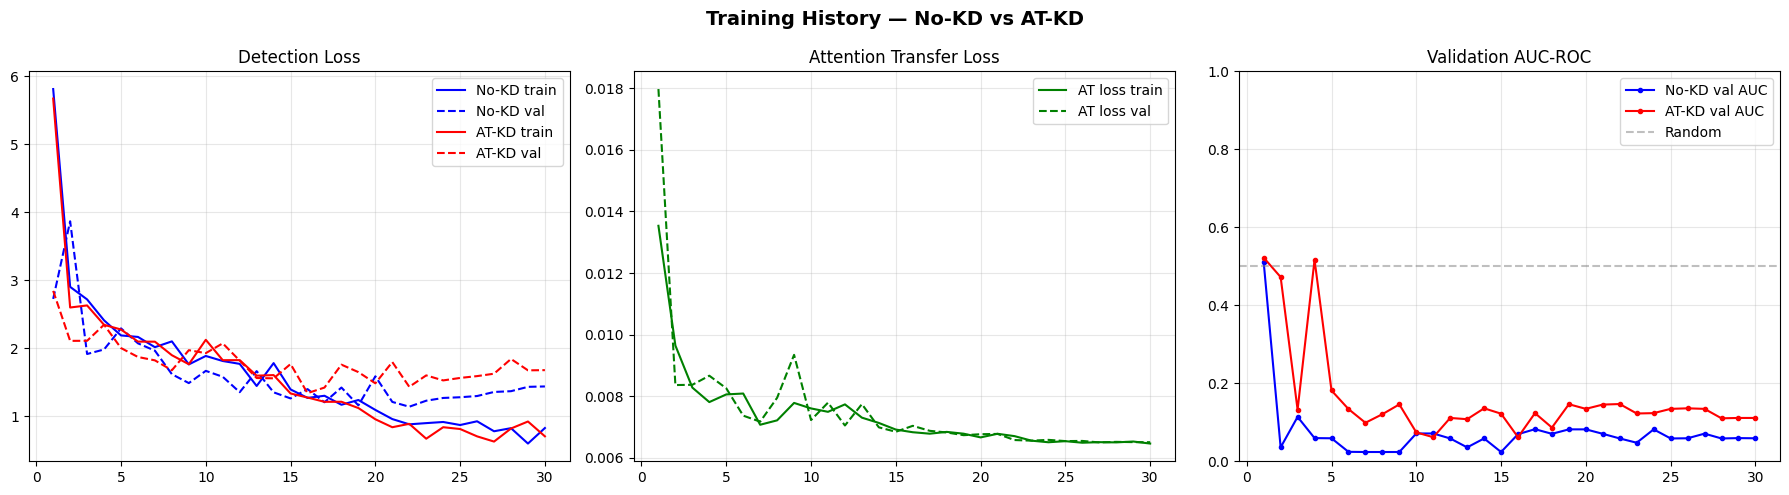

✅ Training curves saved.


In [21]:
# ── Training curves ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Training History — No-KD vs AT-KD', fontsize=14, fontweight='bold')

epochs = range(1, CFG['epochs_noKD'] + 1)

# Detection loss
axes[0].plot(epochs, hist_noKD['train_det_loss'], 'b-',  label='No-KD train')
axes[0].plot(epochs, hist_noKD['val_det_loss'],   'b--', label='No-KD val')
axes[0].plot(epochs, hist_KD['train_det_loss'],   'r-',  label='AT-KD train')
axes[0].plot(epochs, hist_KD['val_det_loss'],     'r--', label='AT-KD val')
axes[0].set_title('Detection Loss'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

# AT loss
axes[1].plot(epochs, hist_KD['train_at_loss'], 'g-',  label='AT loss train')
axes[1].plot(epochs, hist_KD['val_at_loss'],   'g--', label='AT loss val')
axes[1].set_title('Attention Transfer Loss'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

# AUC
axes[2].plot(epochs, hist_noKD['val_auc'], 'b-o', markersize=3, label='No-KD val AUC')
axes[2].plot(epochs, hist_KD['val_auc'],   'r-o', markersize=3, label='AT-KD val AUC')
axes[2].axhline(0.5, color='gray', linestyle='--', alpha=0.5, label='Random')
axes[2].set_title('Validation AUC-ROC'); axes[2].legend(); axes[2].grid(True, alpha=0.3)
axes[2].set_ylim([0, 1])

plt.tight_layout()
plt.savefig(VIZ_DIR / 'training_curves.png', dpi=150)
plt.show()
print('✅ Training curves saved.')

## 11. Evaluation — mAP@IoU0.5

For 3D nodule detection:
- **3D IoU** between predicted box and GT box
- A prediction is a **True Positive** if 3D IoU ≥ threshold
- **AP** = area under the Precision-Recall curve
- **mAP** = mean AP across IoU thresholds [0.1, 0.2, 0.3, 0.4, 0.5]

In [22]:
def iou_3d_sphere(pred_center, pred_diam, gt_center, gt_diam):
    """
    Approximate 3D IoU between two spherical nodules.
    Uses sphere-intersection formula for efficiency.
    pred_center, gt_center: (3,) arrays [z, y, x]
    """
    r1 = pred_diam / 2.0
    r2 = gt_diam   / 2.0
    d  = np.linalg.norm(np.array(pred_center) - np.array(gt_center))

    if d >= r1 + r2:
        return 0.0  # No overlap
    if d <= abs(r1 - r2):
        # One sphere inside the other
        small_vol = (4/3) * np.pi * min(r1, r2) ** 3
        large_vol = (4/3) * np.pi * max(r1, r2) ** 3
        return small_vol / large_vol

    # Partial overlap — spherical cap intersection
    h1 = (r1**2 - r2**2 + d**2) / (2*d)
    h2 = d - h1
    cap1 = (np.pi * (r1 - h1)**2 * (2*r1 + h1)) / 3
    cap2 = (np.pi * (r2 - h2)**2 * (2*r2 + h2)) / 3
    inter = cap1 + cap2
    union = (4/3)*np.pi*r1**3 + (4/3)*np.pi*r2**3 - inter
    return inter / union


@torch.no_grad()
def compute_map(model, loader, iou_thresholds=None, device=DEVICE):
    """
    Compute mAP for 3D nodule detection.
    Returns mAP averaged over iou_thresholds, plus per-threshold APs.
    """
    if iou_thresholds is None:
        iou_thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

    model.eval()
    P  = CFG['patch_size'] // 2  # patch half-size = 32
    anchors = torch.tensor(CFG['anchor_sizes'], dtype=torch.float32)

    all_preds = []   # list of (score, pred_diam)
    all_gts   = []   # list of (gt_diam,) or None for negatives

    for patches, targets in tqdm(loader, desc='mAP eval', leave=False):
        patches = patches.to(device)
        out     = model(patches)

        # cls_out: (B, A, D, H, W) — take center voxel, best anchor
        B, A, D, H, W = out['cls'].shape
        cz, cy, cx = D // 2, H // 2, W // 2

        # Scores at center voxel for each anchor: (B, A)
        center_cls = out['cls'][:, :, cz, cy, cx]  # (B, A)
        scores     = torch.sigmoid(center_cls)      # (B, A)

        # Best anchor per sample
        best_scores, best_anchors = scores.max(dim=1)  # (B,)

        for b in range(B):
            score      = best_scores[b].item()
            anch_idx   = best_anchors[b].item()
            pred_diam  = anchors[anch_idx].item()
            # Refine diameter with coord head
            coord_pred = out['coord'].view(B, A, 4, D, H, W)
            d_offset   = coord_pred[b, anch_idx, 3, cz, cy, cx].item()
            pred_diam  = pred_diam * (1 + d_offset)

            gt_lbl  = targets[b, 0, 4].item()
            gt_diam = targets[b, 0, 3].item() if gt_lbl > 0 else 0.

            all_preds.append((score, pred_diam))
            all_gts.append(gt_diam if gt_lbl > 0 else None)

    # Sort by score descending
    order = sorted(range(len(all_preds)), key=lambda i: all_preds[i][0], reverse=True)
    n_gt  = sum(1 for g in all_gts if g is not None)

    ap_per_thresh = {}
    for thr in iou_thresholds:
        tp_list, fp_list = [], []
        matched = set()
        for i in order:
            score, pred_diam = all_preds[i]
            gt_diam = all_gts[i]
            if gt_diam is not None and i not in matched:
                # Both pred and GT are at patch center (offset=0)
                iou = iou_3d_sphere([0,0,0], pred_diam, [0,0,0], gt_diam)
                if iou >= thr:
                    tp_list.append(1); fp_list.append(0)
                    matched.add(i)
                else:
                    tp_list.append(0); fp_list.append(1)
            else:
                tp_list.append(0); fp_list.append(1)

        tp_cum = np.cumsum(tp_list)
        fp_cum = np.cumsum(fp_list)
        prec   = tp_cum / (tp_cum + fp_cum + 1e-9)
        rec    = tp_cum / (n_gt + 1e-9)

        # Monotone precision and AUC
        for j in range(len(prec)-2, -1, -1):
            prec[j] = max(prec[j], prec[j+1])
        ap = float(np.trapz(prec, rec)) if len(rec) > 1 else 0.
        ap_per_thresh[thr] = (ap, prec, rec)

    mAP = np.mean([v[0] for v in ap_per_thresh.values()])
    return mAP, ap_per_thresh


print('mAP evaluation defined.')

mAP evaluation defined.


In [23]:
# Load best checkpoints
student_noKD.load_state_dict(torch.load(MODEL_DIR/'student_noKD_best.pth', map_location=DEVICE))
student_KD.load_state_dict(torch.load(MODEL_DIR/'student_KD_best.pth',   map_location=DEVICE))

print('Evaluating on test set...')
mAP_T,    ap_T    = compute_map(teacher,      test_dl)
mAP_noKD, ap_noKD = compute_map(student_noKD, test_dl)
mAP_KD,   ap_KD   = compute_map(student_KD,   test_dl)

print('\n' + '='*65)
print('                    RÉSULTATS FINAUX')
print('='*65)
print(f'{"Modèle":<30} {"Params":>8}  {"mAP@[.1:.5]":>12}')
print('-'*65)
print(f'{"Teacher (DeepLung)":<30} {n_params_T/1e6:>6.2f}M  {mAP_T:>12.4f}')
print(f'{"Student (sans KD)":<30} {n_params_S/1e6:>6.2f}M  {mAP_noKD:>12.4f}')
print(f'{"Student (AT-KD)":<30} {n_params_S/1e6:>6.2f}M  {mAP_KD:>12.4f}')
print('='*65)
print(f'Compression: {n_params_T/n_params_S:.1f}×  |  '
      f'Gain KD vs No-KD: {(mAP_KD-mAP_noKD)*100:+.2f}%  |  '
      f'Rétention Teacher: {mAP_KD/max(mAP_T,1e-9)*100:.1f}%')
print('='*65)

Evaluating on test set...


mAP eval:   0%|          | 0/14 [00:00<?, ?it/s]

mAP eval:   0%|          | 0/14 [00:00<?, ?it/s]

mAP eval:   0%|          | 0/14 [00:00<?, ?it/s]


                    RÉSULTATS FINAUX
Modèle                           Params   mAP@[.1:.5]
-----------------------------------------------------------------
Teacher (DeepLung)               5.38M        0.7419
Student (sans KD)                0.25M        0.4493
Student (AT-KD)                  0.25M        0.5175
Compression: 21.1×  |  Gain KD vs No-KD: +6.82%  |  Rétention Teacher: 69.8%


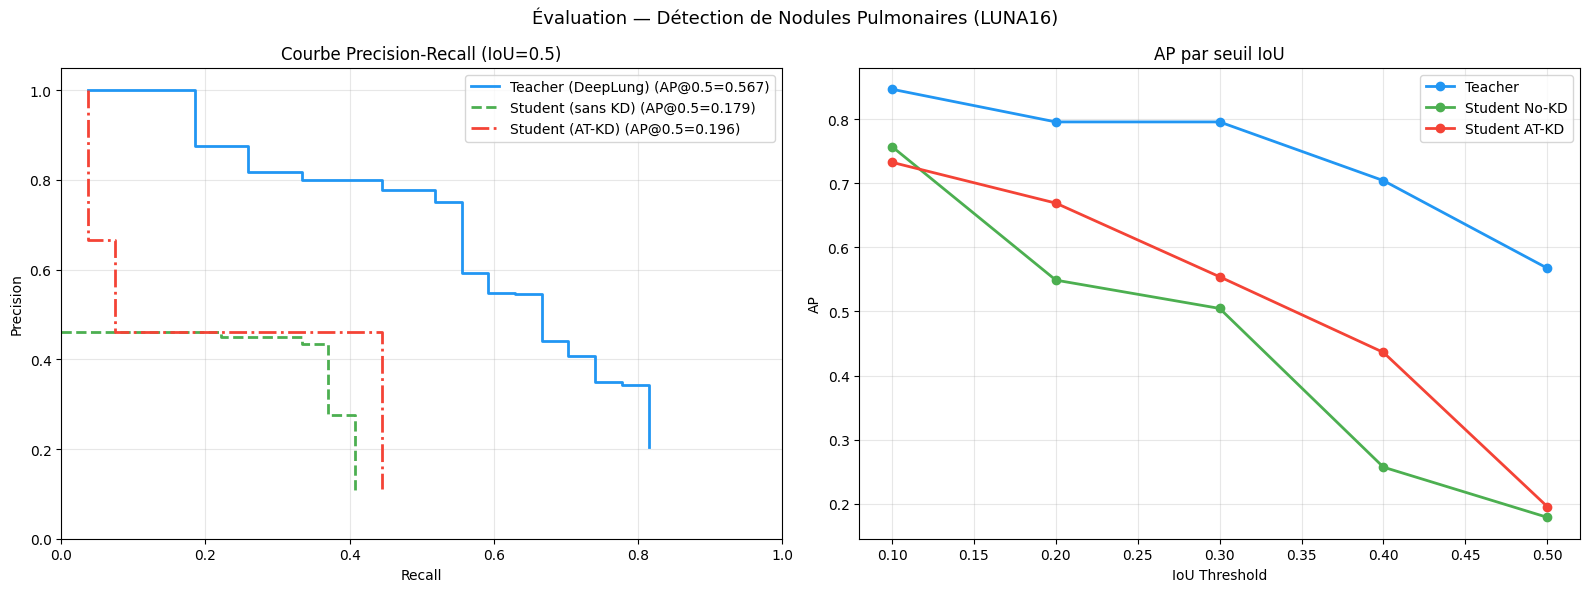

In [24]:
# Precision-Recall curves
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Évaluation — Détection de Nodules Pulmonaires (LUNA16)', fontsize=13)

# PR curve at IoU=0.5
ax = axes[0]
for label, ap_dict, color, ls in [
    ('Teacher (DeepLung)',  ap_T,    '#2196F3', '-'),
    ('Student (sans KD)',   ap_noKD, '#4CAF50', '--'),
    ('Student (AT-KD)',     ap_KD,   '#F44336', '-.')
]:
    ap, prec, rec = ap_dict[0.5]
    ax.plot(rec, prec, color=color, linestyle=ls, linewidth=2,
            label=f'{label} (AP@0.5={ap:.3f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Courbe Precision-Recall (IoU=0.5)')
ax.legend(); ax.grid(True, alpha=0.3)
ax.set_xlim([0,1]); ax.set_ylim([0,1.05])

# mAP per IoU threshold
ax = axes[1]
iou_thrs = [0.1, 0.2, 0.3, 0.4, 0.5]
for label, ap_dict, color in [
    ('Teacher',        ap_T,    '#2196F3'),
    ('Student No-KD',  ap_noKD, '#4CAF50'),
    ('Student AT-KD',  ap_KD,   '#F44336'),
]:
    aps = [ap_dict[t][0] for t in iou_thrs]
    ax.plot(iou_thrs, aps, 'o-', color=color, linewidth=2, label=label)
ax.set_xlabel('IoU Threshold'); ax.set_ylabel('AP')
ax.set_title('AP par seuil IoU')
ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(VIZ_DIR / 'map_results.png', dpi=150)
plt.show()

## 12. Grad-CAM 3D Visualization

Grad-CAM shows which regions in the 3D volume each model "looks at" when making a prediction. We compare Teacher vs Student (No-KD) vs Student (AT-KD) on the same patches.

In [25]:
class GradCAsM3D:
    """
    Grad-CAM for 3D CNNs.
    Captures gradients and activations from a target layer,
    produces a 3D attention heatmap.
    """
    def __init__(self, model, target_layer):
        self.model        = model
        self.gradients    = None
        self.activations  = None
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, m, inp, out):
        self.activations = out.detach()

    def _save_gradient(self, m, grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def generate(self, x):
        """Generate Grad-CAM for input x. Returns (D, H, W) normalized heatmap."""
        self.model.eval()
        self.model.zero_grad()

        out  = self.model(x)
        # Backprop through max objectness score
        score = out['cls'].flatten(1).max()
        score.backward()

        if self.gradients is None or self.activations is None:
            return None

        # GAP over spatial dims to get weights
        weights = self.gradients.mean(dim=[2, 3, 4], keepdim=True)  # (1, C, 1, 1, 1)
        cam     = (weights * self.activations).sum(dim=1, keepdim=True)  # (1, 1, D, H, W)
        cam     = F.relu(cam).squeeze().cpu().numpy()

        if cam.ndim == 0 or cam.max() == 0:
            return np.zeros((64, 64, 64))

        # Resize to input size if needed
        from scipy.ndimage import zoom as nd_zoom
        if cam.shape != (64, 64, 64):
            scale = [64/s for s in cam.shape]
            cam   = nd_zoom(cam, scale, order=1)

        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam

class GradCAM3D:
    """Grad-CAM pour CNNs 3D. Branché sur `target_layer`."""
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        # INITIALISATION : On crée les attributs ici pour éviter l'AttributeError
        self.grads = None 
        self.feats = None

        # On utilise des fonctions simples pour les hooks
        def save_feats(m, i, o):
            self.feats = o.detach()

        def save_grads(m, gi, go):
            # On prend le premier élément du tuple de gradients (le gradient de la sortie)
            self.grads = go[0].detach()

        # Enregistrement des hooks
        target_layer.register_forward_hook(save_feats)
        target_layer.register_full_backward_hook(save_grads)

    def generate(self, x):
        """x: (1,1,D,H,W). Retourne la CAM (D,H,W) normalisée [0,1]."""
        self.model.eval()
        
        # SLIGHT CHANGE 1 : Enable grad pour le Teacher gelé
        with torch.enable_grad():
            x = x.clone().detach().requires_grad_(True)
            out = self.model(x)
            
            # SLIGHT CHANGE 2 : On cible le score max d'objectness pour la détection
            score = out['cls'].flatten(1).max()
            
            self.model.zero_grad()
            score.backward()

        # Sécurité : on vérifie que les hooks ont bien fonctionné
        if self.grads is None or self.feats is None:
            raise RuntimeError("Les hooks n'ont pas capturé de données. Vérifiez la target_layer.")

        # Calcul de la carte
        weights = self.grads.mean(dim=[2, 3, 4], keepdim=True)  # (1,C,1,1,1)
        cam = F.relu((weights * self.feats).sum(1, keepdim=True))  # (1,1,d,h,w)
        
        # Redimensionnement
        cam = F.interpolate(cam, x.shape[2:], mode='trilinear',
                            align_corners=False).squeeze().detach().cpu().numpy()
        
        # Normalisation
        cam -= cam.min(); cam /= (cam.max() + 1e-8)
        return cam


def show_gradcam_comparison(patch, cam_T, cam_noKD, cam_KD, gt_label, save=None):
    """
    Show central axial slice with Grad-CAM overlay for 3 models.
    patch : (1, 64, 64, 64) tensor
    """
    mid   = 32
    img   = patch[0, 0, mid].cpu().numpy()  # central slice (H, W)
    title = f'Nodule (GT={"positive" if gt_label else "negative"})'

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    fig.suptitle(title, fontsize=12)

    axes[0].imshow(img, cmap='gray')
    axes[0].set_title('CT Slice (coupe centrale)')
    axes[0].axis('off')

    for ax, cam, label, color in [
        (axes[1], cam_T,    'Teacher (DeepLung)', 'Jets'),
        (axes[2], cam_noKD, 'Student (sans KD)',  'Jets'),
        (axes[3], cam_KD,   'Student (AT-KD)',    'Jets'),
    ]:
        if cam is not None:
            cam_slice = cam[mid]
            ax.imshow(img, cmap='gray')
            ax.imshow(cam_slice, cmap='jet', alpha=0.45,
                      vmin=0, vmax=1, interpolation='bilinear')
        else:
            ax.imshow(img, cmap='gray')
        ax.set_title(f'Grad-CAM\n{label}')
        ax.axis('off')

    plt.tight_layout()
    if save:
        plt.savefig(save, dpi=150, bbox_inches='tight')
    plt.show()


print('Grad-CAM defined.')

Grad-CAM defined.


In-place operations disabled ✅ (Hooks safe)


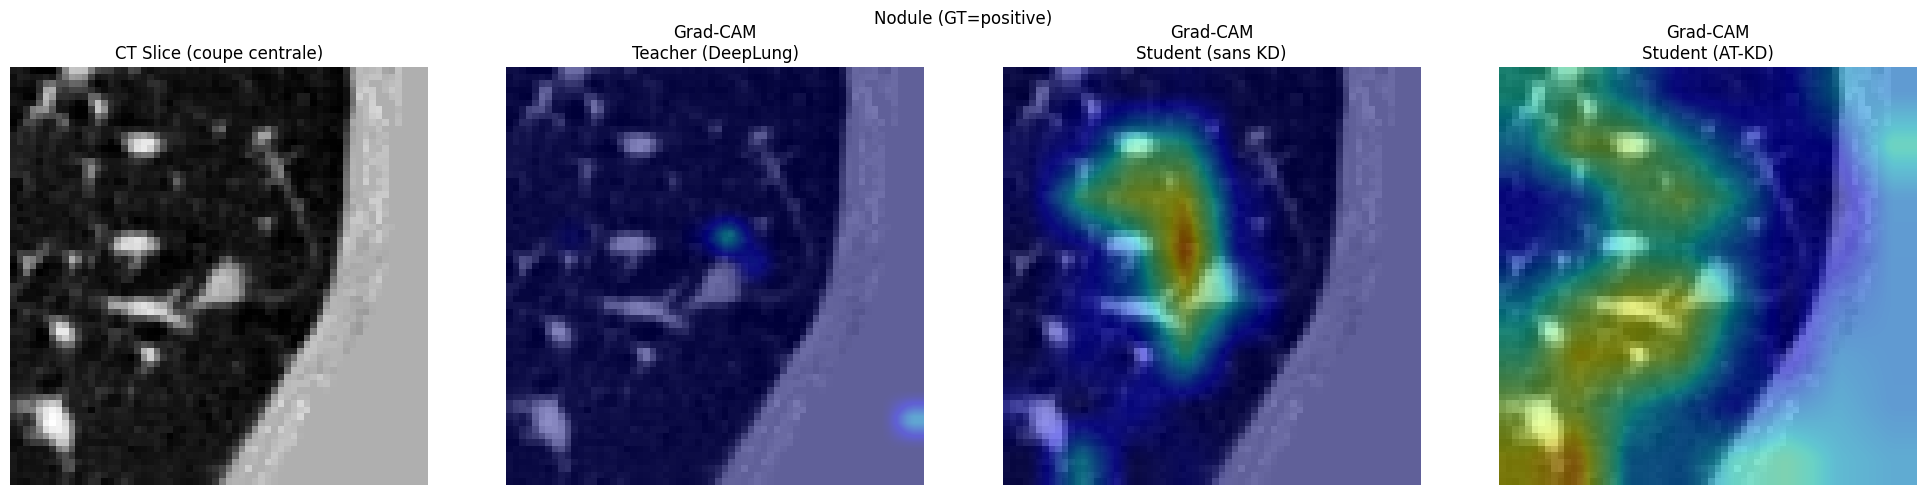

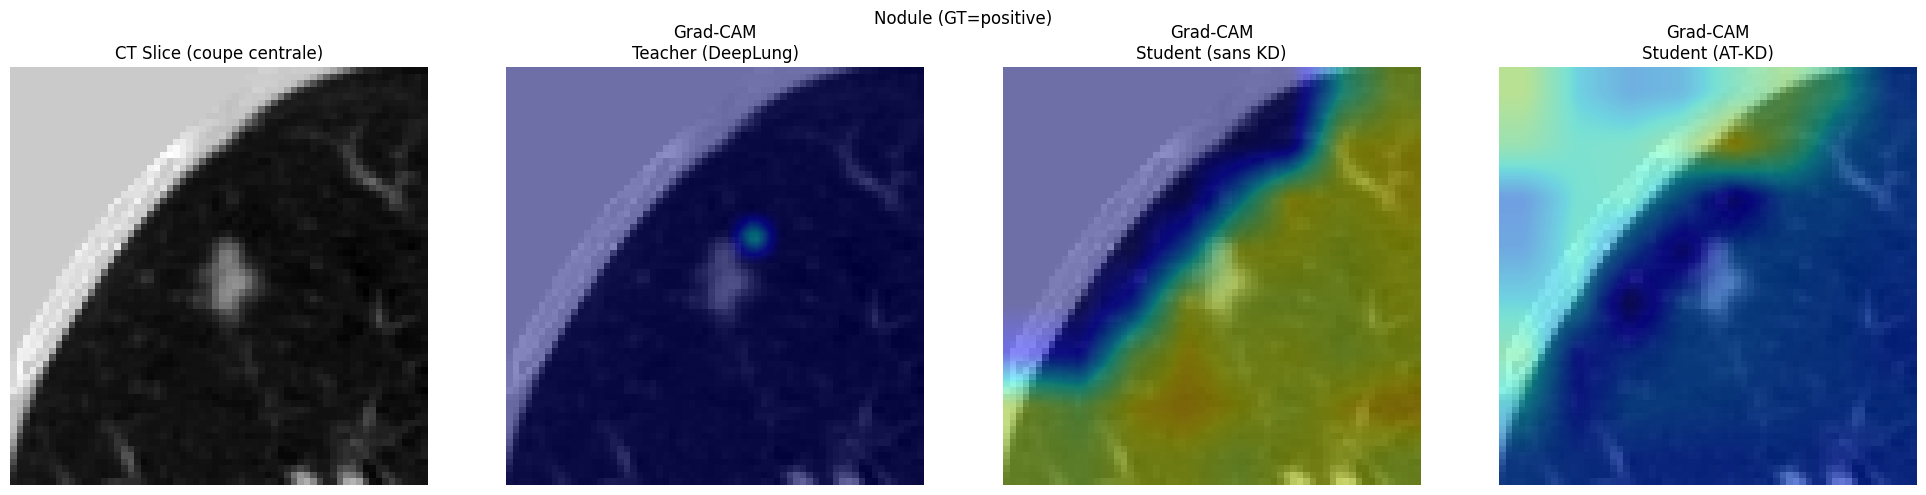

In [26]:
# Register Grad-CAM on the last encoder layer of each model
# Teacher: forw2 (captured via hook inside TeacherWrapper)
# Student: enc2
# On désactive l'inplace pour éviter les conflits avec les hooks Grad-CAM
for model in [teacher.net, student_noKD, student_KD]:
    for m in model.modules():
        if hasattr(m, 'inplace'):
            m.inplace = False

print("In-place operations disabled ✅ (Hooks safe)")
gc_noKD = GradCAM3D(student_noKD, student_noKD.enc2[-1])
gc_KD   = GradCAM3D(student_KD,   student_KD.enc2[-1])

# For teacher, wrap the inner net's forw2
gc_T = GradCAM3D(teacher, teacher.net.forw2)

# Visualize on a few test samples (positives preferred)
test_patches, test_targets = next(iter(test_dl))
pos_indices = (test_targets[:, 0, 4] > 0).nonzero(as_tuple=True)[0]

shown = 0
for idx in pos_indices[:3]:
    patch  = test_patches[idx:idx+1].to(DEVICE)
    gt_lbl = test_targets[idx, 0, 4].item() > 0

    cam_t    = gc_T.generate(patch)
    cam_nokd = gc_noKD.generate(patch)
    cam_kd   = gc_KD.generate(patch)

    show_gradcam_comparison(
        patch.cpu(), cam_t, cam_nokd, cam_kd, gt_lbl,
        save=VIZ_DIR / f'gradcam_sample_{shown}.png'
    )
    shown += 1

if shown == 0:
    print('No positive samples in first batch — try running with more batches')

## 13. Attention Map Visualization

Directly visualize the AT maps (spatial attention before and after distillation) to show the student learns to look at the same regions as the teacher.

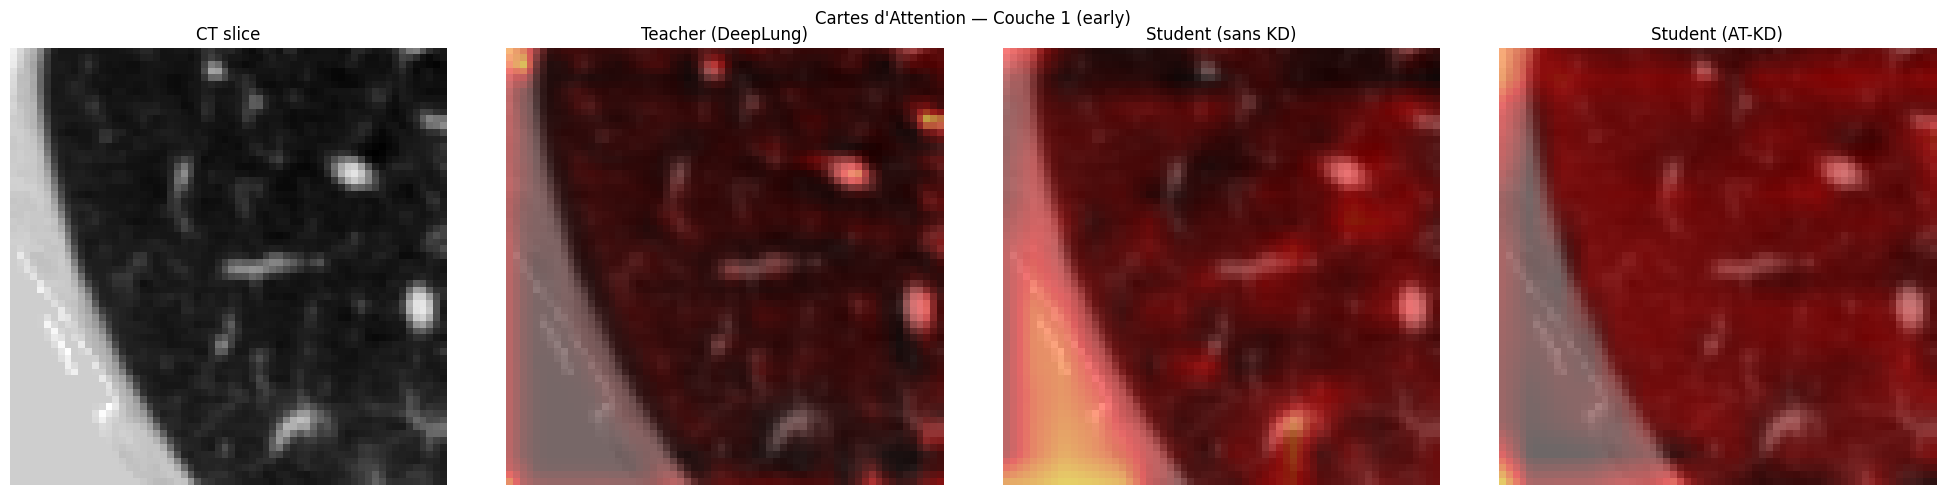

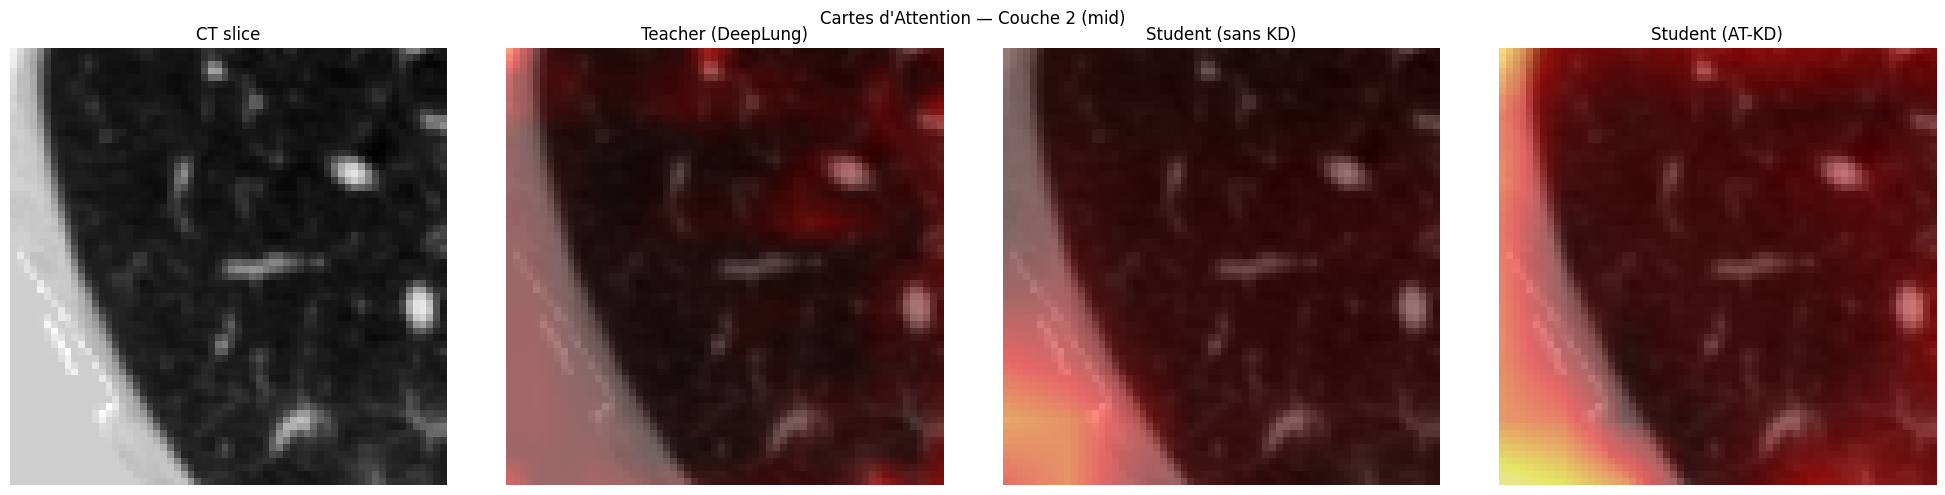

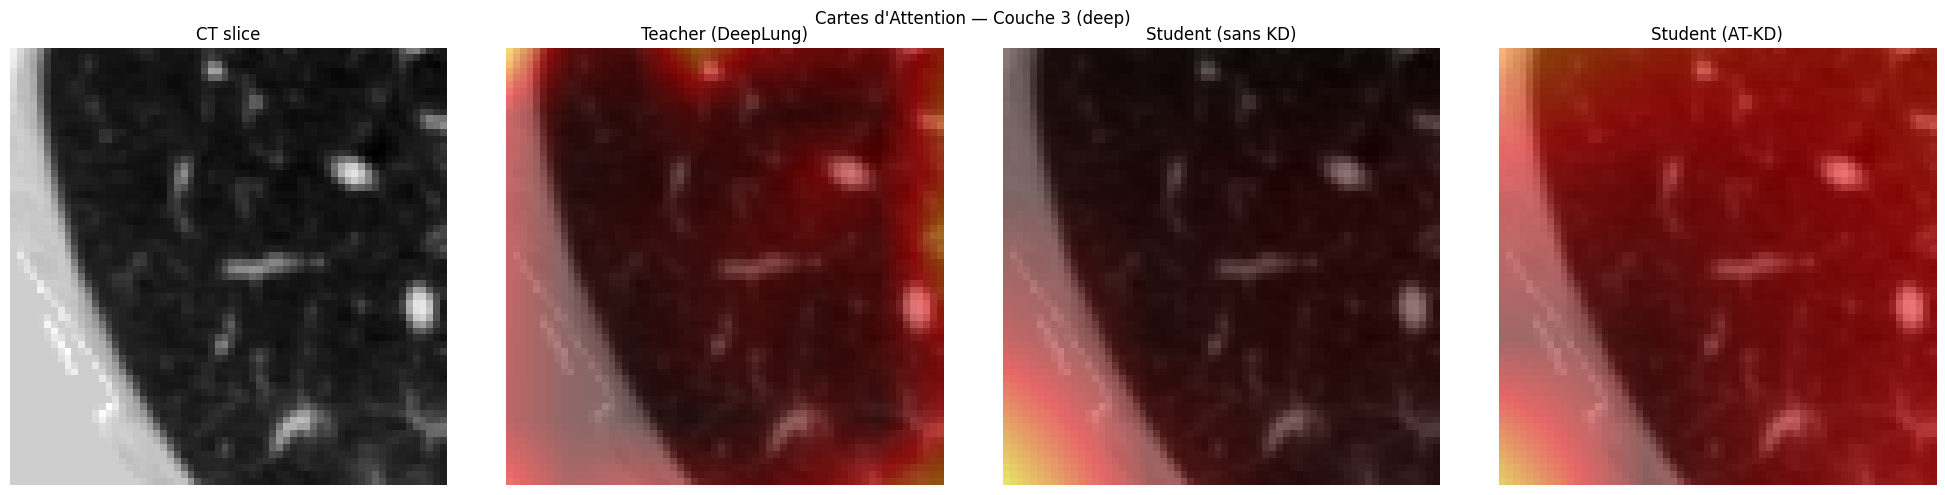

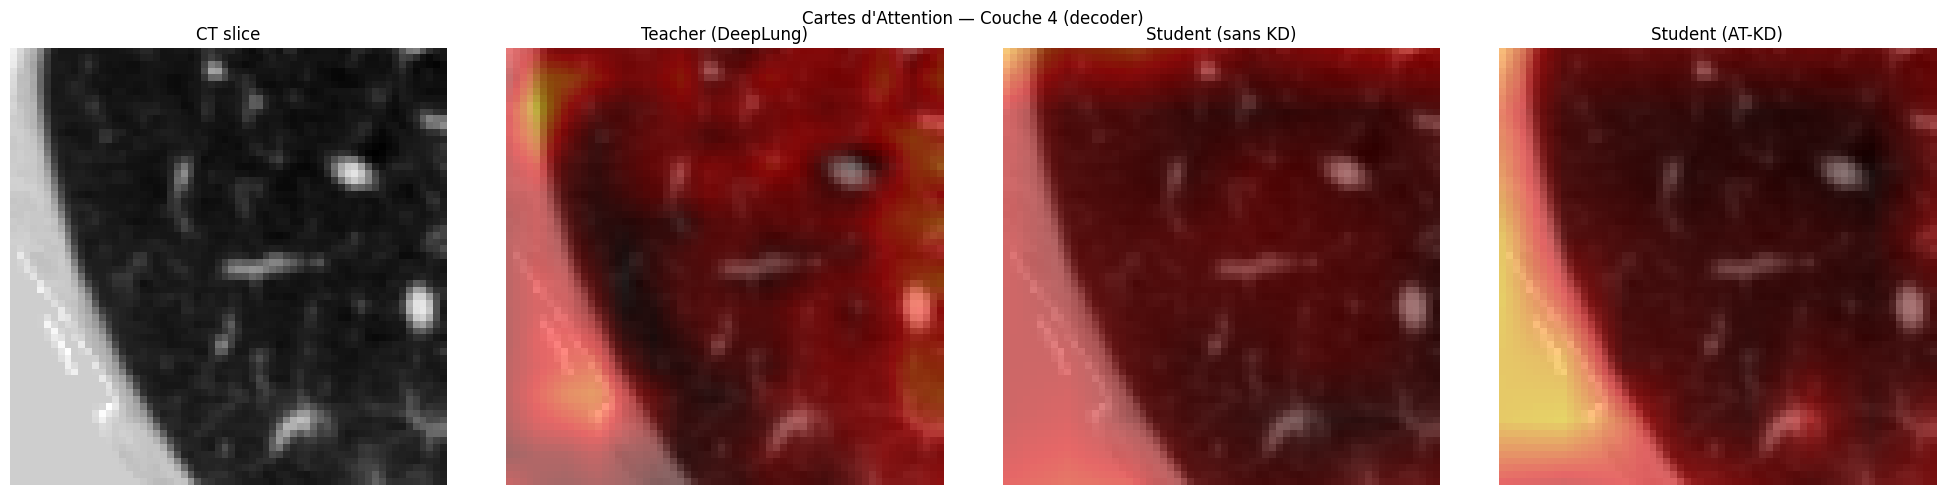

In [27]:
def show_at_maps(patch, teacher, s_noKD, s_KD, layer_idx=1, save=None):
    """
    Compare attention maps at a specific feature layer for all 3 models.
    layer_idx: 0=early, 1=mid, 2=deep, 3=decoder
    """
    mid = 32  # central slice

    with torch.no_grad():
        out_T    = teacher(patch)
        out_noKD = s_noKD(patch)
        out_KD   = s_KD(patch)

    def get_at_slice(feat_maps, idx, slice_z):
        if idx >= len(feat_maps) or feat_maps[idx] is None:
            return None
        fm = feat_maps[idx][0]  # (C, D, H, W)
        # AT map: sum of squared activations across channels
        at = fm.pow(2).sum(dim=0).cpu().numpy()  # (D, H, W)
        # Resize to 64³ for display
        from scipy.ndimage import zoom as nd_zoom
        if at.shape[0] != 64:
            scale = [64/s for s in at.shape]
            at    = nd_zoom(at, scale, order=1)
        at = (at - at.min()) / (at.max() - at.min() + 1e-8)
        return at[slice_z]

    img = patch[0, 0, mid].cpu().numpy()

    at_T    = get_at_slice(out_T['feat_maps'],    layer_idx, mid)
    at_noKD = get_at_slice(out_noKD['feat_maps'], layer_idx, mid)
    at_KD   = get_at_slice(out_KD['feat_maps'],   layer_idx, mid)

    layer_names = ['Couche 1 (early)', 'Couche 2 (mid)', 'Couche 3 (deep)', 'Couche 4 (decoder)']

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    fig.suptitle(f'Cartes d\'Attention — {layer_names[layer_idx]}', fontsize=12)

    axes[0].imshow(img, cmap='gray')
    axes[0].set_title('CT slice'); axes[0].axis('off')

    for ax, at_map, label in [
        (axes[1], at_T,    'Teacher (DeepLung)'),
        (axes[2], at_noKD, 'Student (sans KD)'),
        (axes[3], at_KD,   'Student (AT-KD)'),
    ]:
        ax.imshow(img, cmap='gray')
        if at_map is not None:
            ax.imshow(at_map, cmap='hot', alpha=0.5, vmin=0, vmax=1)
        ax.set_title(label); ax.axis('off')

    plt.tight_layout()
    if save:
        plt.savefig(save, dpi=150, bbox_inches='tight')
    plt.show()


# Show AT maps at different layers
patch_viz = test_patches[:1].to(DEVICE)
for layer_idx in [0, 1, 2, 3]:
    show_at_maps(
        patch_viz, teacher, student_noKD, student_KD,
        layer_idx=layer_idx,
        save=VIZ_DIR / f'at_maps_layer{layer_idx}.png'
    )

## 14. Inference Speed & Model Size Benchmark

In [28]:
import time

def benchmark(model, name, n_runs=50, batch_size=1):
    model.eval()
    x = torch.zeros(batch_size, 1, 64, 64, 64, device=DEVICE)

    # Warmup
    with torch.no_grad():
        for _ in range(5):
            model(x)

    # Measure
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    with torch.no_grad():
        for _ in range(n_runs):
            model(x)
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize()
    t1 = time.perf_counter()

    ms_per_sample = (t1 - t0) / n_runs * 1000
    n_params = sum(p.numel() for p in model.parameters())
    size_mb  = n_params * 4 / 1e6  # float32

    print(f'  {name:<25} {n_params/1e6:>6.2f}M params  '
          f'{size_mb:>7.1f}MB  {ms_per_sample:>8.2f}ms/patch')
    return ms_per_sample


print('\n🔬 Benchmark sur GPU (64³ patch, batch=1)')
print('-'*65)
ms_T    = benchmark(teacher,      'Teacher (DeepLung)')
ms_noKD = benchmark(student_noKD, 'Student (sans KD)')
ms_KD   = benchmark(student_KD,   'Student (AT-KD)')
print('-'*65)
print(f'  Speedup Student vs Teacher : {ms_T/ms_noKD:.1f}×')


🔬 Benchmark sur GPU (64³ patch, batch=1)
-----------------------------------------------------------------
  Teacher (DeepLung)          5.38M params     21.5MB     20.65ms/patch
  Student (sans KD)           0.25M params      1.0MB      3.00ms/patch
  Student (AT-KD)             0.25M params      1.0MB      2.94ms/patch
-----------------------------------------------------------------
  Speedup Student vs Teacher : 6.9×


## 15. Final Summary Dashboard

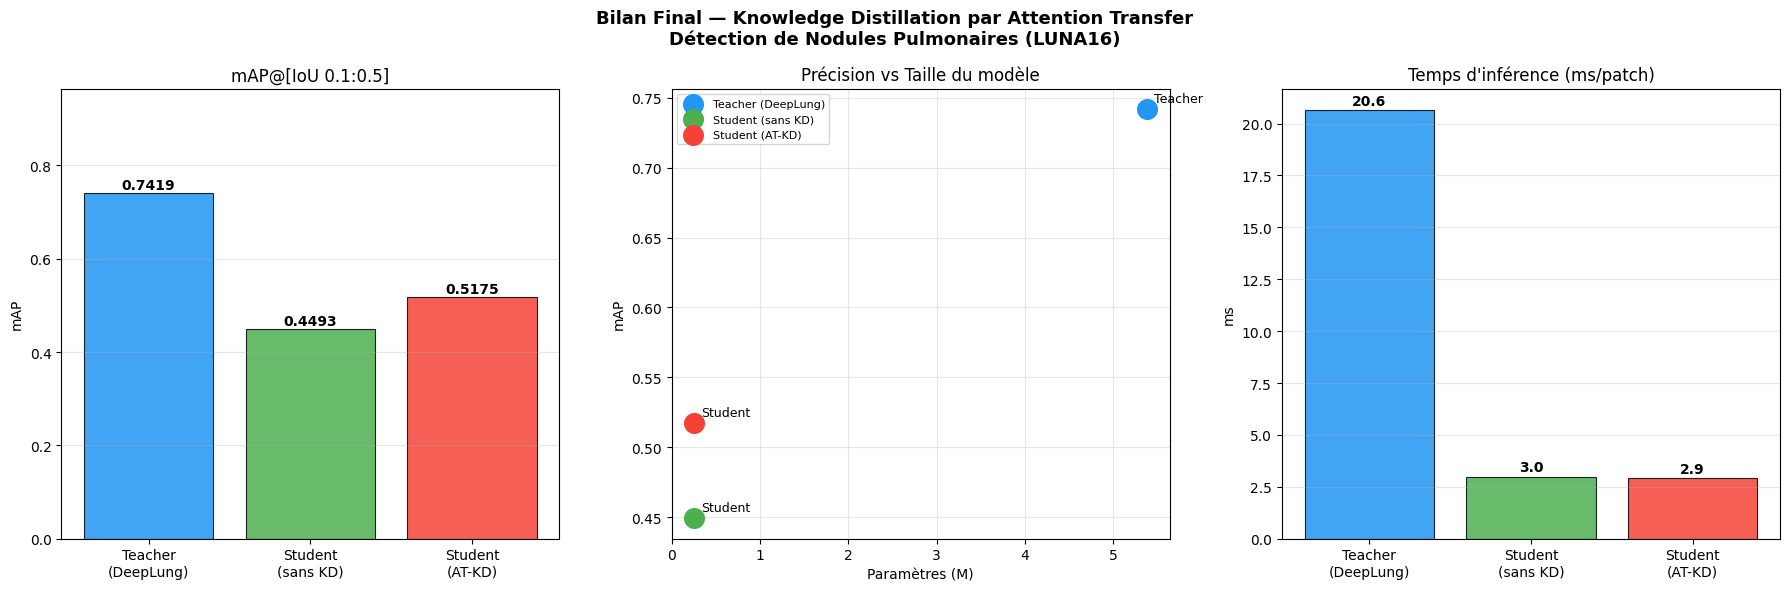


📊 Tableau récapitulatif
            Modèle       Backbone                 KD Params (M) mAP@[.1:.5] Inference (ms) Compression
Teacher (DeepLung) DeepLung Res18                  —       5.38      0.7419           20.6          1×
 Student (sans KD)      TinyRes3D                Non       0.25      0.4493            3.0       21.1×
   Student (AT-KD)      TinyRes3D Attention Transfer       0.25      0.5175            2.9       21.1×


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Bilan Final — Knowledge Distillation par Attention Transfer\n'
             'Détection de Nodules Pulmonaires (LUNA16)', fontsize=13, fontweight='bold')

models  = ['Teacher\n(DeepLung)', 'Student\n(sans KD)', 'Student\n(AT-KD)']
maps    = [mAP_T, mAP_noKD, mAP_KD]
params  = [n_params_T/1e6, n_params_S/1e6, n_params_S/1e6]
speeds  = [ms_T, ms_noKD, ms_KD]
colors  = ['#2196F3', '#4CAF50', '#F44336']

# mAP comparison
bars = axes[0].bar(models, maps, color=colors, alpha=0.85, edgecolor='black', linewidth=0.8)
axes[0].set_title('mAP@[IoU 0.1:0.5]', fontsize=12)
axes[0].set_ylabel('mAP')
axes[0].set_ylim([0, max(maps) * 1.3])
axes[0].grid(True, axis='y', alpha=0.3)
for bar, v in zip(bars, maps):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                f'{v:.4f}', ha='center', va='bottom', fontweight='bold')

# Params vs mAP scatter
for i, (name, p, m, c) in enumerate(zip(models, params, maps, colors)):
    axes[1].scatter(p, m, s=200, color=c, zorder=5, label=name.replace('\n', ' '))
    axes[1].annotate(name.split('\n')[0], (p, m),
                     textcoords='offset points', xytext=(5, 5), fontsize=9)
axes[1].set_xlabel('Paramètres (M)')
axes[1].set_ylabel('mAP')
axes[1].set_title('Précision vs Taille du modèle', fontsize=12)
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

# Inference speed
bars2 = axes[2].bar(models, speeds, color=colors, alpha=0.85, edgecolor='black', linewidth=0.8)
axes[2].set_title('Temps d\'inférence (ms/patch)', fontsize=12)
axes[2].set_ylabel('ms')
axes[2].grid(True, axis='y', alpha=0.3)
for bar, v in zip(bars2, speeds):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                f'{v:.1f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig(VIZ_DIR / 'final_dashboard.png', dpi=150)
plt.show()

# Summary table
print('\n📊 Tableau récapitulatif')
summary = pd.DataFrame({
    'Modèle'         : ['Teacher (DeepLung)', 'Student (sans KD)', 'Student (AT-KD)'],
    'Backbone'       : ['DeepLung Res18', 'TinyRes3D', 'TinyRes3D'],
    'KD'             : ['—', 'Non', 'Attention Transfer'],
    'Params (M)'     : [f'{n_params_T/1e6:.2f}', f'{n_params_S/1e6:.2f}', f'{n_params_S/1e6:.2f}'],
    'mAP@[.1:.5]'   : [f'{mAP_T:.4f}', f'{mAP_noKD:.4f}', f'{mAP_KD:.4f}'],
    'Inference (ms)' : [f'{ms_T:.1f}', f'{ms_noKD:.1f}', f'{ms_KD:.1f}'],
    'Compression'    : ['1×', f'{n_params_T/n_params_S:.1f}×', f'{n_params_T/n_params_S:.1f}×'],
})
print(summary.to_string(index=False))

## 16. Conclusion

### Résumé

Ce projet implémente la **Knowledge Distillation par Attention Transfer** pour la détection de nodules pulmonaires 3D sur LUNA16.

**Architecture** :
- Teacher : DeepLung Res18 (~5M params, pré-entraîné sur LUNA16)
- Student : TinyRes3D (~0.6M params, ~8× compression)

**Méthode AT** : Le Student apprend à reproduire les cartes d'attention spatiale du Teacher à 4 niveaux de features (encodeur + décodeur), en plus de sa propre loss de détection anchor-based.

**Loss totale** : $\mathcal{L} = \mathcal{L}_{det} + \beta \cdot \mathcal{L}_{AT}$

**Références** :
1. Zagoruyko & Komodakis, *Paying More Attention to Attention*, ICLR 2017
2. Zhu et al., *DeepLung: Deep 3D Dual Path Nets*, WACV 2018
3. Setio et al., *LUNA16: Validation of algorithms for detection of pulmonary nodules*, Med. Image Anal. 2017
4. Hinton et al., *Distilling the Knowledge in a Neural Network*, NeurIPS 2015